In [1]:
#библиотеки для создания графиков
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb

#библиотеки для работы с табличными данными (pandas для таблиц, numpy для ускорения вычислений)
import pandas as pd
import numpy as np

#модуль для статистического анализа
from scipy import stats

#библиотека для работы с пространственными данными
import geopandas as gpd

#единые настройки стиля по умолчанию для графиокв
plt.rcParams.update({
    #размер фигуры и четкость
    "figure.figsize": (13, 7),
    "figure.dpi": 300,  
    
    #размеры шрифтов
    "font.size": 14,
    "axes.titlesize": 12,           
    "axes.labelsize": 10,          
    "xtick.labelsize": 10,          
    "ytick.labelsize": 10,        
    "legend.fontsize": 10,

    #жирность
    "axes.titleweight": "bold",  
    "figure.titleweight": "bold",
    
    #отступы
    "axes.titlepad": 15,          
    "axes.labelpad": 10,         
    
    #толщина линий и размер точек на графиках
    "lines.linewidth": 2.5,
    "lines.markersize": 7,
    
    #сетка
    "grid.alpha": 0.5,
    "grid.linestyle": "--",
    
    #рамка и отступы легенды
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.borderpad": 0.8,
    
    "font.family": "Verdana"
})

In [2]:
#загружаем основной датасет по онкологическим заболеваниям по регионам РФ (1997-2024)
df_oncology = pd.read_csv("data/oncology_1997_2024.csv", delimiter=";")

#дополнительный датасет с демографическими показателями по муниципалитетам РФ (2005-2023)
df_demo = pd.read_csv("data/demography_2005_2023.csv", delimiter=";")

#оптимизируем работу с таблицами через введение категорий
cat_oncology = ["sex", "indicator_name", "indicator_section", "age", "object_name", "object_level", "nosology_name", "nosology_code"]
for col in cat_oncology:
    if col in df_oncology.columns:
        df_oncology[col] = df_oncology[col].astype("category")


#фиксим архангельскую и тюменскую области, чтобы потом join правильно работал
geo_name_mapping = {"Тюменская область без автономных округов": "Тюменская область","Архангельская область без автономного округа": "Архангельская область", 
                   "Тюменская область (без автономных округов)": "Тюменская область","Архангельская область (без автономного округа)": "Архангельская область"}
df_oncology["join_name"] = df_oncology["object_name"].astype(str).replace(geo_name_mapping)
df_demo["join_name"] = df_demo["object_name"].astype(str).replace(geo_name_mapping)

#также заранее подгрущим geodataframe c регионами РФ и перепроецируем, proj c сайта projection wizard
gdf_russia = gpd.read_file("data/russia_regions.geojson")
russia_crs = "+proj=aea +lat_1=50 +lat_2=70 +lat_0=56 +lon_0=100 +x_0=0 +y_0=0 +ellps=WGS84 +datum=WGS84 +units=m +no_defs"
gdf_russia = gdf_russia.to_crs(russia_crs)

# Исследование онкологической заболеваемости и смертности в Российской Федерации (1997–2024 гг.)

---
В данном исследовании мной будут проанализированы основные паттерны пространственного распределения и врменной динамики показателей онкологической динамики по регионам РФ. Также будут рассмотрены различия показателей по поло-возратсным группам.

# Данные

### Используемые наборы данных
Для проведения комплексного статистического и пространственно-демографического анализа используются три независимых датасет:
1. **`df_oncology` (`data/oncology_1997_2024.csv`):** Набор данных об онкологической заболеваемости и смертности в разрезе субъектов РФ, половых и возрастных категорий за период с 1997 по 2024 гг. Аггрегированные данные ежегодных отчетов инстиутта им. Герцена. (https://tochno.st/datasets/cancer_incidence)
2. **`df_demo` (`data/demography_2005_2023.csv`):** Муниципальная и региональная демографическая статистика РФ за 2005–2023 гг. Аггрегированные и первично обработанные данные Росстата (https://tochno.st/datasets/bdmo)
3. **`gdf_russia` (`data/russia_regions.geojson`):** Пространственные векторные границы субъектов Российской Федерации (https://github.com/hairymax/offline_russia_plotly/blob/main/data/russia_regions.geojson?ysclid=mvhbqoyyan311685916).

### Обработка данных
* **Унификация названий субъектов:** Наименования типа *«Тюменская область без автономных округов»* и *«Архангельская область без автономного округа»* приведены к единому стандарту для корректного связывания данных между собой
* **Перепроецирование геоданных:** Картографический слой `gdf_russia` переведён из географической системы координат WGS84 в равновеликую проекцию Альберса, использующуюся для карт РФ

### Целостность данных
Проверка на целостность показала, что:

In [3]:
def analyze_missing_values(df, df_name) :
    """Выводит сводную статистику по пропущенным значениям в датасете.
        Params:
        df -- dataframe для анализа
        df_name -- название dataframe
    """
    total_rows = len(df)
    missing_series = df.isna().sum()
    missing_cols = missing_series[missing_series > 0]
    
    if missing_cols.empty:
        print(f"В датасете {df_name} пропусков не обнаружено.\n")
    else:
        print(f"В датасете {df_name}:")
        for column, n_empty in missing_cols.items():
            pct = n_empty / total_rows
            print(f"В колонке '{column}' пропущено {n_empty:,} из {total_rows:,} значений ({pct:.1%}).")
        print()

#Анализ пропусков в онкологическом датасете
analyze_missing_values(df_oncology, "Онкологические заболевания по регионам РФ (1997–2024)")

#Анализ пропусков в демографическом датасете
analyze_missing_values(df_demo, "Демографические показатели по муниципалитетам РФ (2005–2023)")

В датасете Онкологические заболевания по регионам РФ (1997–2024) пропусков не обнаружено.

В датасете Демографические показатели по муниципалитетам РФ (2005–2023) пропусков не обнаружено.



Это обусловлено тем, что данные уже прошли первичную обработку при аггрегировании в датасеты

In [4]:
#сразу вынесем всопмогательную функцию для быстрого получения срезов основного датасета по годам с нужными параметрами
def get_oncology_slice(
    indicator, 
    year="all", 
    sex="Оба пола",
    age="Всего",
    nosology_name="Все злокачественные новообразования",
    object_level="Страна"
):
    """Формирует очищенный срез онкологических данных по заданным фильтрам
    
    Params:
    indicator -- необходимый показатель (Абсолютное число новых случаев заболевания, Абсолютное число умерших, Общий коэффициент заболеваемости,
       Общий коэффициент смертности, Ошибка (для стандартизованного коэффициента заболеваемости), Ошибка (для стандартизованного коэффициента смертности)',
       Стандартизованный коэффициент заболеваемости, Стандартизованный коэффициент смертности)
    year -- временной диапазон, может принимать значения типа:
        - int за один конкретный год (например, 2023)
        - list/tuple/range: за диапазон годов (например, [2020, 2021, 2022] или range(2007, 2024))
        - all (string): за все имеющиеся года без фильтрации по времени -- значение по умолчанию
    sex -- пол (Оба пола, Женщины, Мужчины), по умолчанию оба пола
    age -- возрастная группа (0-14 лет, 0-17 лет, Всего), по умолчанию всего
    nosology_name -- разновидность заболевания (полный список представлен в описании данных), по умолчанию аггрегированный показатель
                    при значении all собирает все категории
    object_level -- уровень детализации данных (Регион, Федеральный округ, Страна), по умолчанию страна
    """
    #фильтруем по однозначно заданным категориям через маску
    mask = (
        (df_oncology["indicator_name"] == indicator) &
        (df_oncology["sex"] == sex) &
        (df_oncology["age"] == age) &
        (df_oncology["object_level"] == object_level)
    )
    
    #добавляем фильтрацию по году
    if year != "all":
        if isinstance(year, int):
            mask &= (df_oncology["year"] == year)
        else:
            mask &= (df_oncology["year"].isin(year))

    if  nosology_name != "all":
        mask &= (df_oncology["nosology_name"] == nosology_name)
        
    return df_oncology[mask].copy().sort_values(by="year")

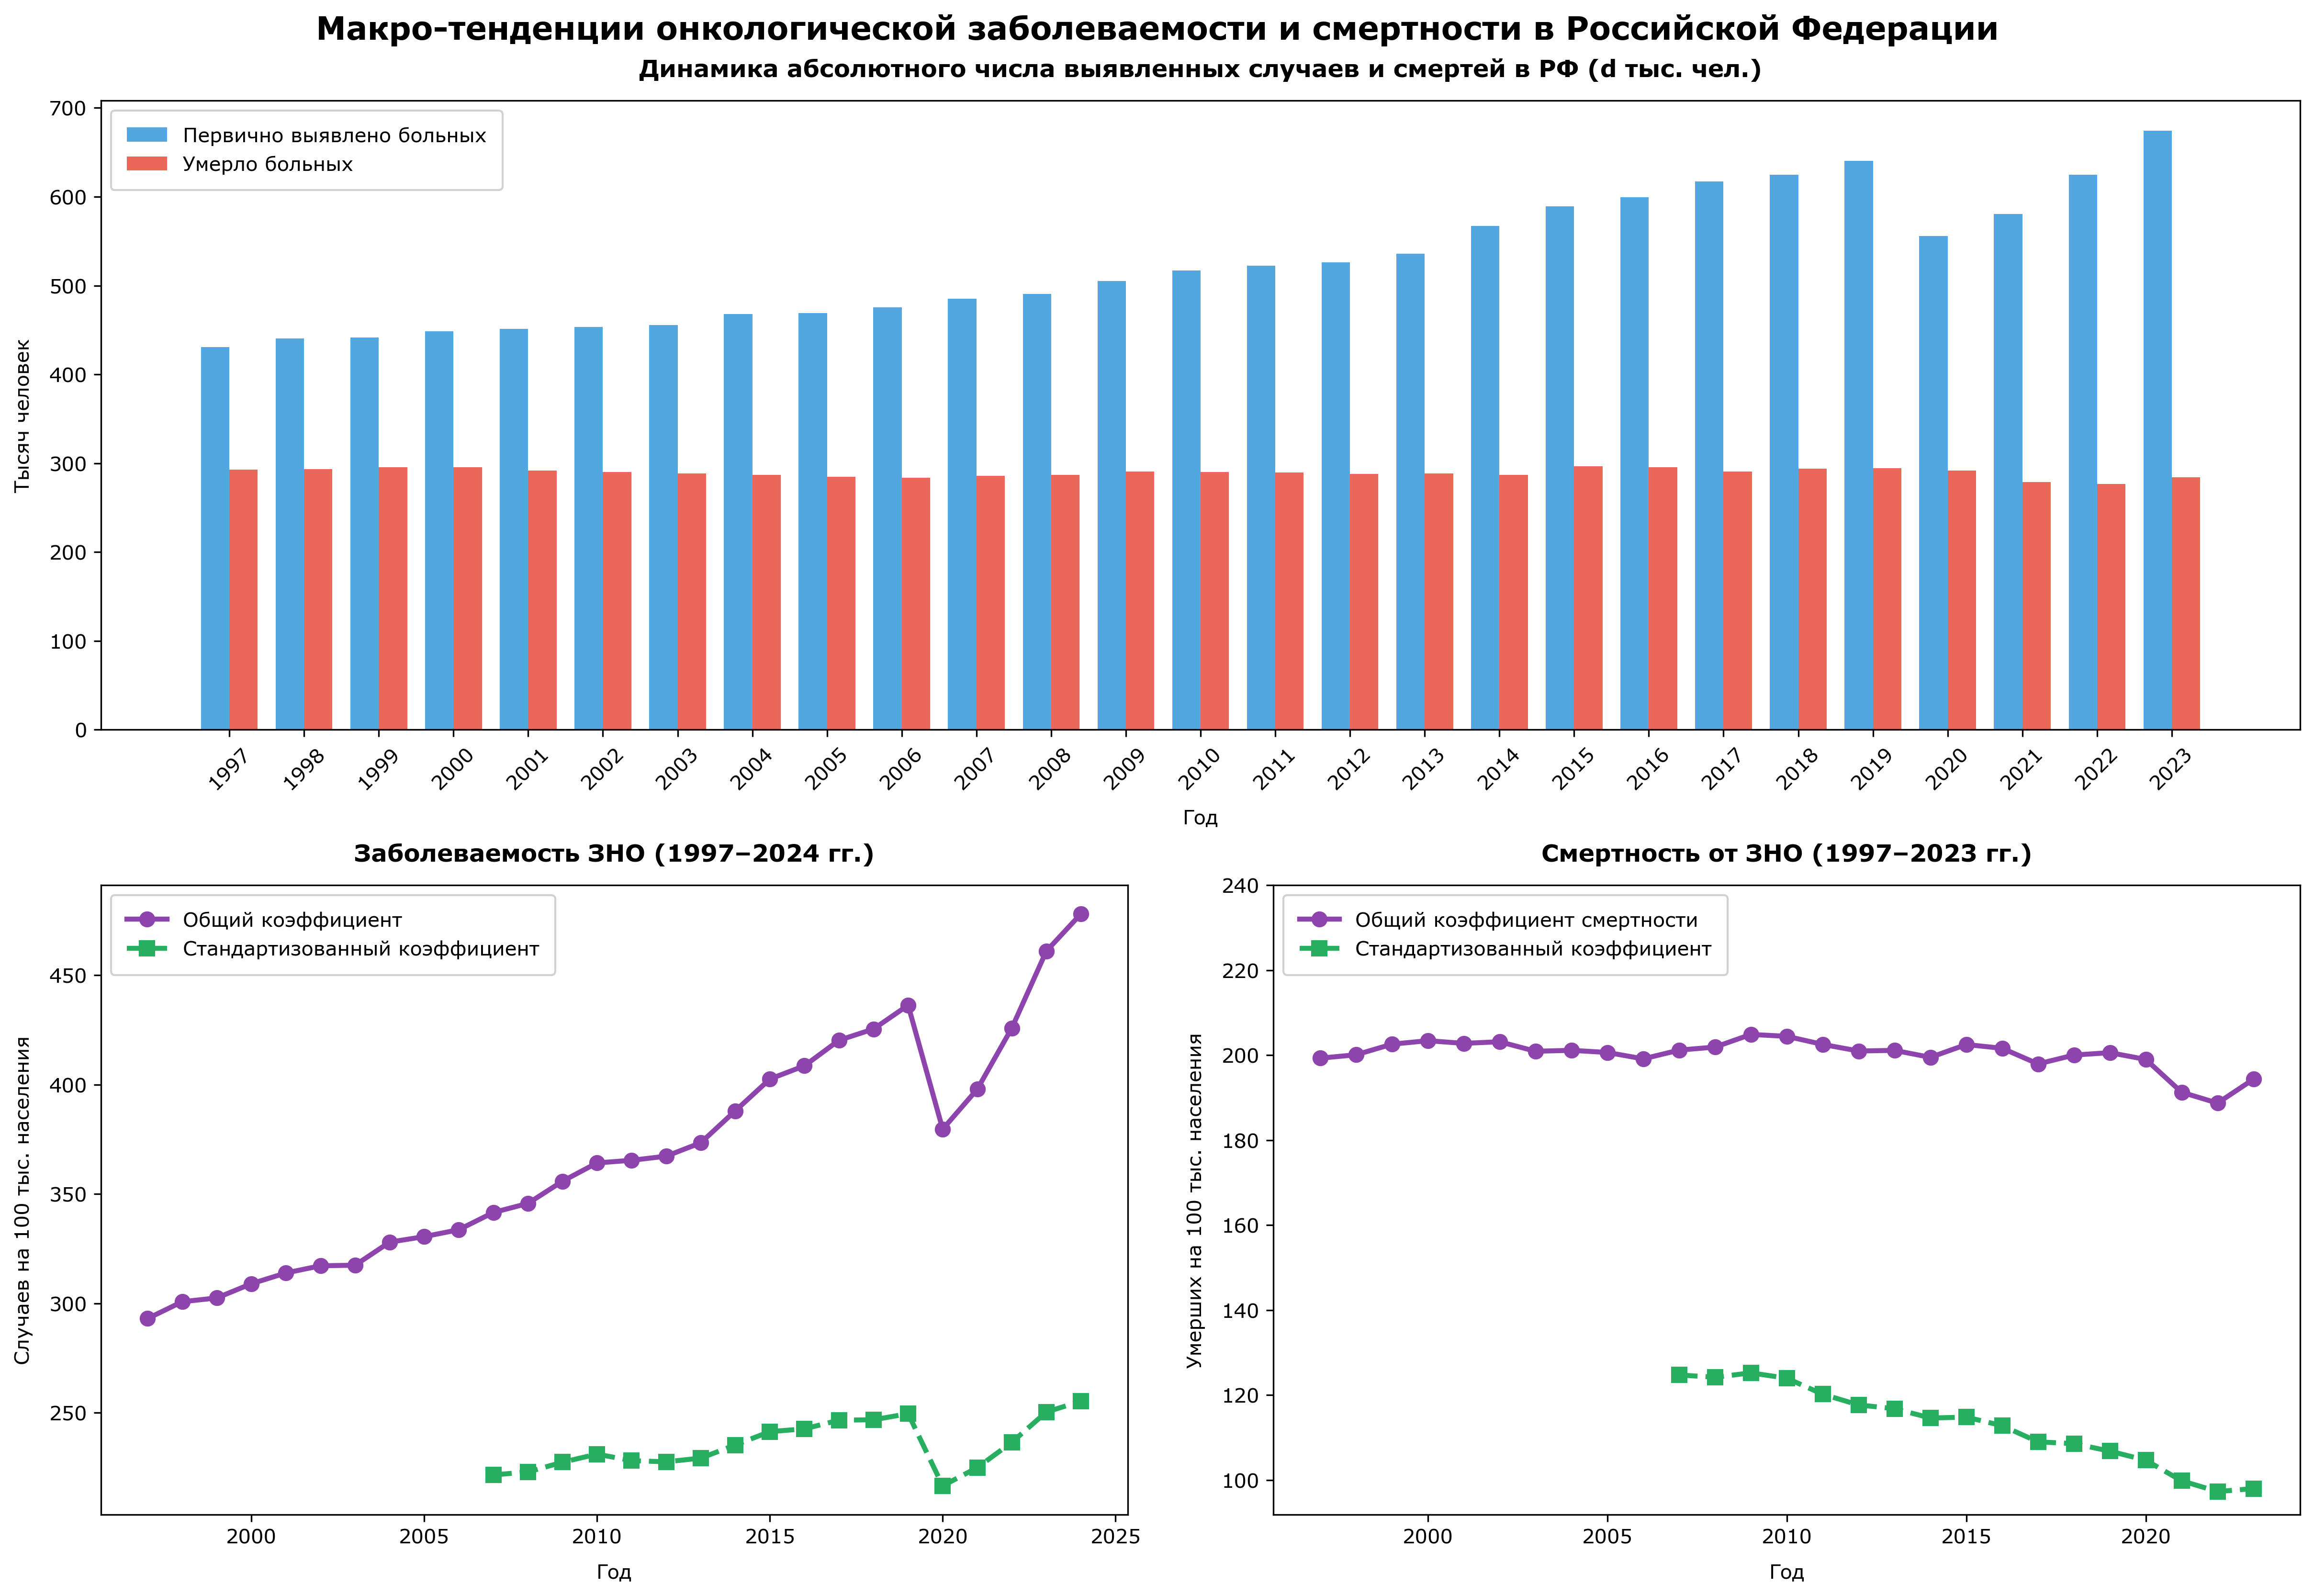

In [5]:
#получаем срезы для коэффициентов заболеваемости
df_morb_crude = get_oncology_slice("Общий коэффициент заболеваемости")
df_morb_std = get_oncology_slice("Стандартизованный коэффициент заболеваемости")

#получаем срезы для коэффициентов смертности
df_mort_crude = get_oncology_slice("Общий коэффициент смертности")
df_mort_std = get_oncology_slice("Стандартизованный коэффициент смертности")

#получаем срезы для абсолютных показателей
df_abs_morb = get_oncology_slice("Абсолютное число новых случаев заболевания")
df_abs_mort = get_oncology_slice("Абсолютное число умерших")

#объединение абсолютных показателей по годам для столбчатой диаграммы
merged_abs = pd.merge(
    df_abs_morb[["year", "indicator_value"]], 
    df_abs_mort[["year", "indicator_value"]], 
    on="year", 
    suffixes=("_morb", "_mort")
)

#строим графики
fig = plt.figure(figsize=(16, 11), constrained_layout=True)
gs = fig.add_gridspec(2, 2) #внутренняя сетка для настроек сабплотов разных размеров

ax = [
    fig.add_subplot(gs[1, 0]),  #ax[0] -- заболеваемость
    fig.add_subplot(gs[1, 1]),  #ax[1] -- смертность
    fig.add_subplot(gs[0, :])   #ax[2] -- абсолютные показатели
]

#заболеваемость
ax[0].plot(df_morb_crude["year"], df_morb_crude["indicator_value"], marker="o", label="Общий коэффициент", color="#8e44ad")
ax[0].plot(df_morb_std["year"], df_morb_std["indicator_value"], marker="s", linestyle="--", label="Стандартизованный коэффициент", color="#27ae60")
ax[0].set_title("Заболеваемость ЗНО (1997–2024 гг.)", pad=12)
ax[0].set_xlabel("Год", labelpad=8)
ax[0].set_ylabel("Случаев на 100 тыс. населения", labelpad=8)
ax[0].legend(loc="upper left")

#смертность
ax[1].plot(df_mort_crude["year"], df_mort_crude["indicator_value"], marker="o", label="Общий коэффициент смертности", color="#8e44ad")
ax[1].plot(df_mort_std["year"], df_mort_std["indicator_value"], marker="s", linestyle="--", label="Стандартизованный коэффициент", color="#27ae60")
ax[1].set_title("Смертность от ЗНО (1997–2023 гг.)", pad=12)
ax[1].set_xlabel("Год", labelpad=8)
ax[1].set_ylabel("Умерших на 100 тыс. населения", labelpad=8)
ax[1].set_ylim(None, 240) #чтобы легенда влезла
ax[1].legend(loc="upper left")

#абсолютные показатели
width = 0.38
years = merged_abs["year"]
x = np.arange(len(years))

ax[2].bar(x - width/2, merged_abs["indicator_value_morb"]/1000, width, label="Первично выявлено больных", color="#3498db", alpha=0.85)
ax[2].bar(x + width/2, merged_abs["indicator_value_mort"]/1000, width, label="Умерло больных", color="#e74c3c", alpha=0.85)
ax[2].set_title("Динамика абсолютного числа выявленных случаев и смертей в РФ (d тыс. чел.)", pad=12)
ax[2].set_xlabel("Год", labelpad=8)
ax[2].set_ylabel("Тысяч человек", labelpad=8)
ax[2].set_xticks(x)
ax[2].set_xticklabels(years, rotation=45)
ax[2].legend(loc="upper left")

#общий заголовок
fig.suptitle("Макро-тенденции онкологической заболеваемости и смертности в Российской Федерации", fontsize=16, fontweight="bold")
plt.show()

### Динамика показателей по всей России
Если взглянуть на общую динамику онкологической заболеваемости и смертности в России, то первым делом в глаза бросается существенная разница между динамикой заболеваемости и смертности. В абсолютных числах первичная выявляемость демонстрирует устойчивый рост: если в 1997 году было зафиксировано около 430 тысяч новых случаев, то к 2023 году этот показатель достиг рекордных 675 тысяч. Единственной заметной аномалией на этом отрезке стал 2020 год, когда на фоне пандемии COVID-19 и приостановки диспансеризации выявляемость временно просела до 550 тысяч, однако уже к 2022–2023 годам тренд полностью восстановился и продолжил рост. В то же время абсолютное число ежегодных смертей от злокачественных новообразований остаётся практически неизменным на протяжении всей четверти века, стабильно удерживаясь в диапазоне 280–300 тысяч человек в год.   
Однако, как известно, абсолютные показатели обычно не вполне подходят для сравнительного анализа, поэтмоу важно также рассмотреть динамику относительных показателей, т.е. коэффициентов заболеваемости и сметности. На графике заболеваемости хорошо виден постоянный рост общего коэффициента (с единственным провалом в 2020). В то же время стандартизованный коэффициент, очищенный от влияния возраста, увеличивается гораздо медленнее — с 220 до 255. Этот увеличивающийся разрыв между линиями косвенно свидетельствует о старении населения: увеличение общего числа заболевших во многом связано именно с ростом доли граждан старших возрастных групп (что будет позже подвтерждено анализом). 
На графике смертности наблюдается ещё более выраженная и позитивная динамика. Хотя общий коэффициент смертности долгие годы колеблется около отметки 190–200 на 100 тыс. населения, стандартизованный показатель смертности планомерно снижается. Это показывает, что на фоне ростущей выявляемости и старения населения реальная смертность от онкопатологий снижается за счёт совершенствования ранней диагностики и повышения эффективности лечения. 

In [7]:
#так как в исходном датасете нет связки регион-фо, то создадим словарь-соответствий
region_to_fo = {
    'Алтайский край': 'СФО',
    'Амурская область': 'ДФО',
    'Архангельская область': 'СЗФО',
    'Архангельская область без автономного округа': 'СЗФО',
    'Астраханская область': 'ЮФО',
    'Белгородская область': 'ЦФО',
    'Брянская область': 'ЦФО',
    'Владимирская область': 'ЦФО',
    'Волгоградская область': 'ЮФО',
    'Вологодская область': 'СЗФО',
    'Воронежская область': 'ЦФО',
    'Еврейская автономная область': 'ДФО',
    'Забайкальский край': 'ДФО',
    'Ивановская область': 'ЦФО',
    'Иркутская область': 'СФО',
    'Кабардино-Балкарская Республика': 'СКФО',
    'Калининградская область': 'СЗФО',
    'Калужская область': 'ЦФО',
    'Камчатский край': 'ДФО',
    'Карачаево-Черкесская Республика': 'СКФО',
    'Кемеровская область': 'СФО',
    'Кировская область': 'ПФО',
    'Костромская область': 'ЦФО',
    'Краснодарский край': 'ЮФО',
    'Красноярский край': 'СФО',
    'Курганская область': 'УФО',
    'Курская область': 'ЦФО',
    'Ленинградская область': 'СЗФО',
    'Липецкая область': 'ЦФО',
    'Магаданская область': 'ДФО',
    'Москва': 'ЦФО',
    'Московская область': 'ЦФО',
    'Мурманская область': 'СЗФО',
    'Ненецкий автономный округ': 'СЗФО',
    'Нижегородская область': 'ПФО',
    'Новгородская область': 'СЗФО',
    'Новосибирская область': 'СФО',
    'Омская область': 'СФО',
    'Оренбургская область': 'ПФО',
    'Орловская область': 'ЦФО',
    'Пензенская область': 'ПФО',
    'Пермский край': 'ПФО',
    'Приморский край': 'ДФО',
    'Псковская область': 'СЗФО',
    'Республика Адыгея': 'ЮФО',
    'Республика Алтай': 'СФО',
    'Республика Башкортостан': 'ПФО',
    'Республика Бурятия': 'ДФО',
    'Республика Дагестан': 'СКФО',
    'Республика Ингушетия': 'СКФО',
    'Республика Калмыкия': 'ЮФО',
    'Республика Карелия': 'СЗФО',
    'Республика Коми': 'СЗФО',
    'Республика Крым': 'ЮФО',
    'Республика Марий Эл': 'ПФО',
    'Республика Мордовия': 'ПФО',
    'Республика Саха (Якутия)': 'ДФО',
    'Республика Северная Осетия — Алания': 'СКФО',
    'Республика Татарстан': 'ПФО',
    'Республика Тыва': 'СФО',
    'Республика Хакасия': 'СФО',
    'Ростовская область': 'ЮФО',
    'Рязанская область': 'ЦФО',
    'Самарская область': 'ПФО',
    'Санкт-Петербург': 'СЗФО',
    'Саратовская область': 'ПФО',
    'Сахалинская область': 'ДФО',
    'Свердловская область': 'УФО',
    'Севастополь': 'ЮФО',
    'Смоленская область': 'ЦФО',
    'Ставропольский край': 'СКФО',
    'Тамбовская область': 'ЦФО',
    'Тверская область': 'ЦФО',
    'Томская область': 'СФО',
    'Тульская область': 'ЦФО',
    'Тюменская область': 'УФО',
    'Тюменская область без автономных округов': 'УФО',
    'Удмуртская Республика': 'ПФО',
    'Ульяновская область': 'ПФО',
    'Хабаровский край': 'ДФО',
    'Ханты-Мансийский автономный округ — Югра': 'УФО',
    'Челябинская область': 'УФО',
    'Чеченская Республика': 'СКФО',
    'Читинская область': 'ДФО',
    'Чувашская Республика': 'ПФО',
    'Чукотский автономный округ': 'ДФО',
    'Ямало-Ненецкий автономный округ': 'УФО',
    'Ярославская область': 'ЦФО'
}

#сделаем функцию для построения набора boxplot по фо с динамикой по годам для показателя
def build_boxplot_dynamics(var_name, y_label, title):
    """Строит показатель по федеральным округам (в формате боксплота с разбросом и нанесёнными значениями регионов) в динамике за 6 опроных годов

        Params:
        var_name -- string, название показателя, динамику которого хотим отразить
        У_label -- string, полпись Оу
        title -- string, название графика
    """
    #выбираем 6 ключевых точек для анализа динамики заболеваемости по фо
    target_years = [2007, 2011, 2015, 2019, 2021, 2023]
    
    #получаем срез по регионам
    df_std_reg = get_oncology_slice(var_name, year=target_years, object_level="Регион")
    
    #чтобы избежать двойного счета подрегионов исключим дублирующие обобщающие строки для регионов с ао
    df_std_reg = df_std_reg[~df_std_reg["object_name"].isin(["Тюменская область", "Архангельская область"])]
    
    #содаем столбец фо для связки фо-регион
    df_std_reg["federal_district"] = df_std_reg["object_name"].map(region_to_fo)
  
    #Фиксируем порядок округов на Ох
    fo_order = ["ЦФО", "СЗФО", "ЮФО", "СКФО", "ПФО", "УФО", "СФО", "ДФО"]
    
    #делаем красивые цвета по фо, чтобы у фо везде был один цвет
    fo_palette = {"ЦФО": "#80b1d3", "СЗФО": "#fdb462", "ЮФО": "#b3de69", "СКФО": "#fb8072", "ПФО": "#bebada", "УФО": "#8dd3c7", "СФО": "#fccde5", "ДФО": "#bc80bd"}
    
    #создаём sublplot 
    fig, axes = plt.subplots(2, 3, figsize=(18, 11), sharey=True, constrained_layout=True)
    axes = axes.flatten() #двумерный массив осей развернем в одномерный для удобсвта

    for i, yr in enumerate(target_years):
        ax = axes[i]
        df_yr = df_std_reg[df_std_reg["year"] == yr]
        
        #для каждого года строим разброс для фо
        sns.boxplot(data=df_yr, x="federal_district", y="indicator_value", hue="federal_district",
                    order=fo_order,ax=ax, palette=fo_palette,fliersize=0,boxprops=dict(alpha=0.7))
        
        #и наносим точки регионов
        sns.stripplot(data=df_yr, x="federal_district", y="indicator_value",order=fo_order,ax=ax,  color="#2c3e50",alpha=0.6, jitter=0.2, size=4.5)
        
        ax.set_title(f"{yr} год", fontsize=13, fontweight="bold", pad=10)
        ax.set_xlabel("")
        ax.tick_params(axis='x', labelsize=10)
        if i % 3 == 0:
            ax.set_ylabel(y_label, labelpad=10) #общая подпись по Оу
    
    #общее название
    fig.suptitle(title,  fontsize=16, fontweight="bold")
    
    plt.show()

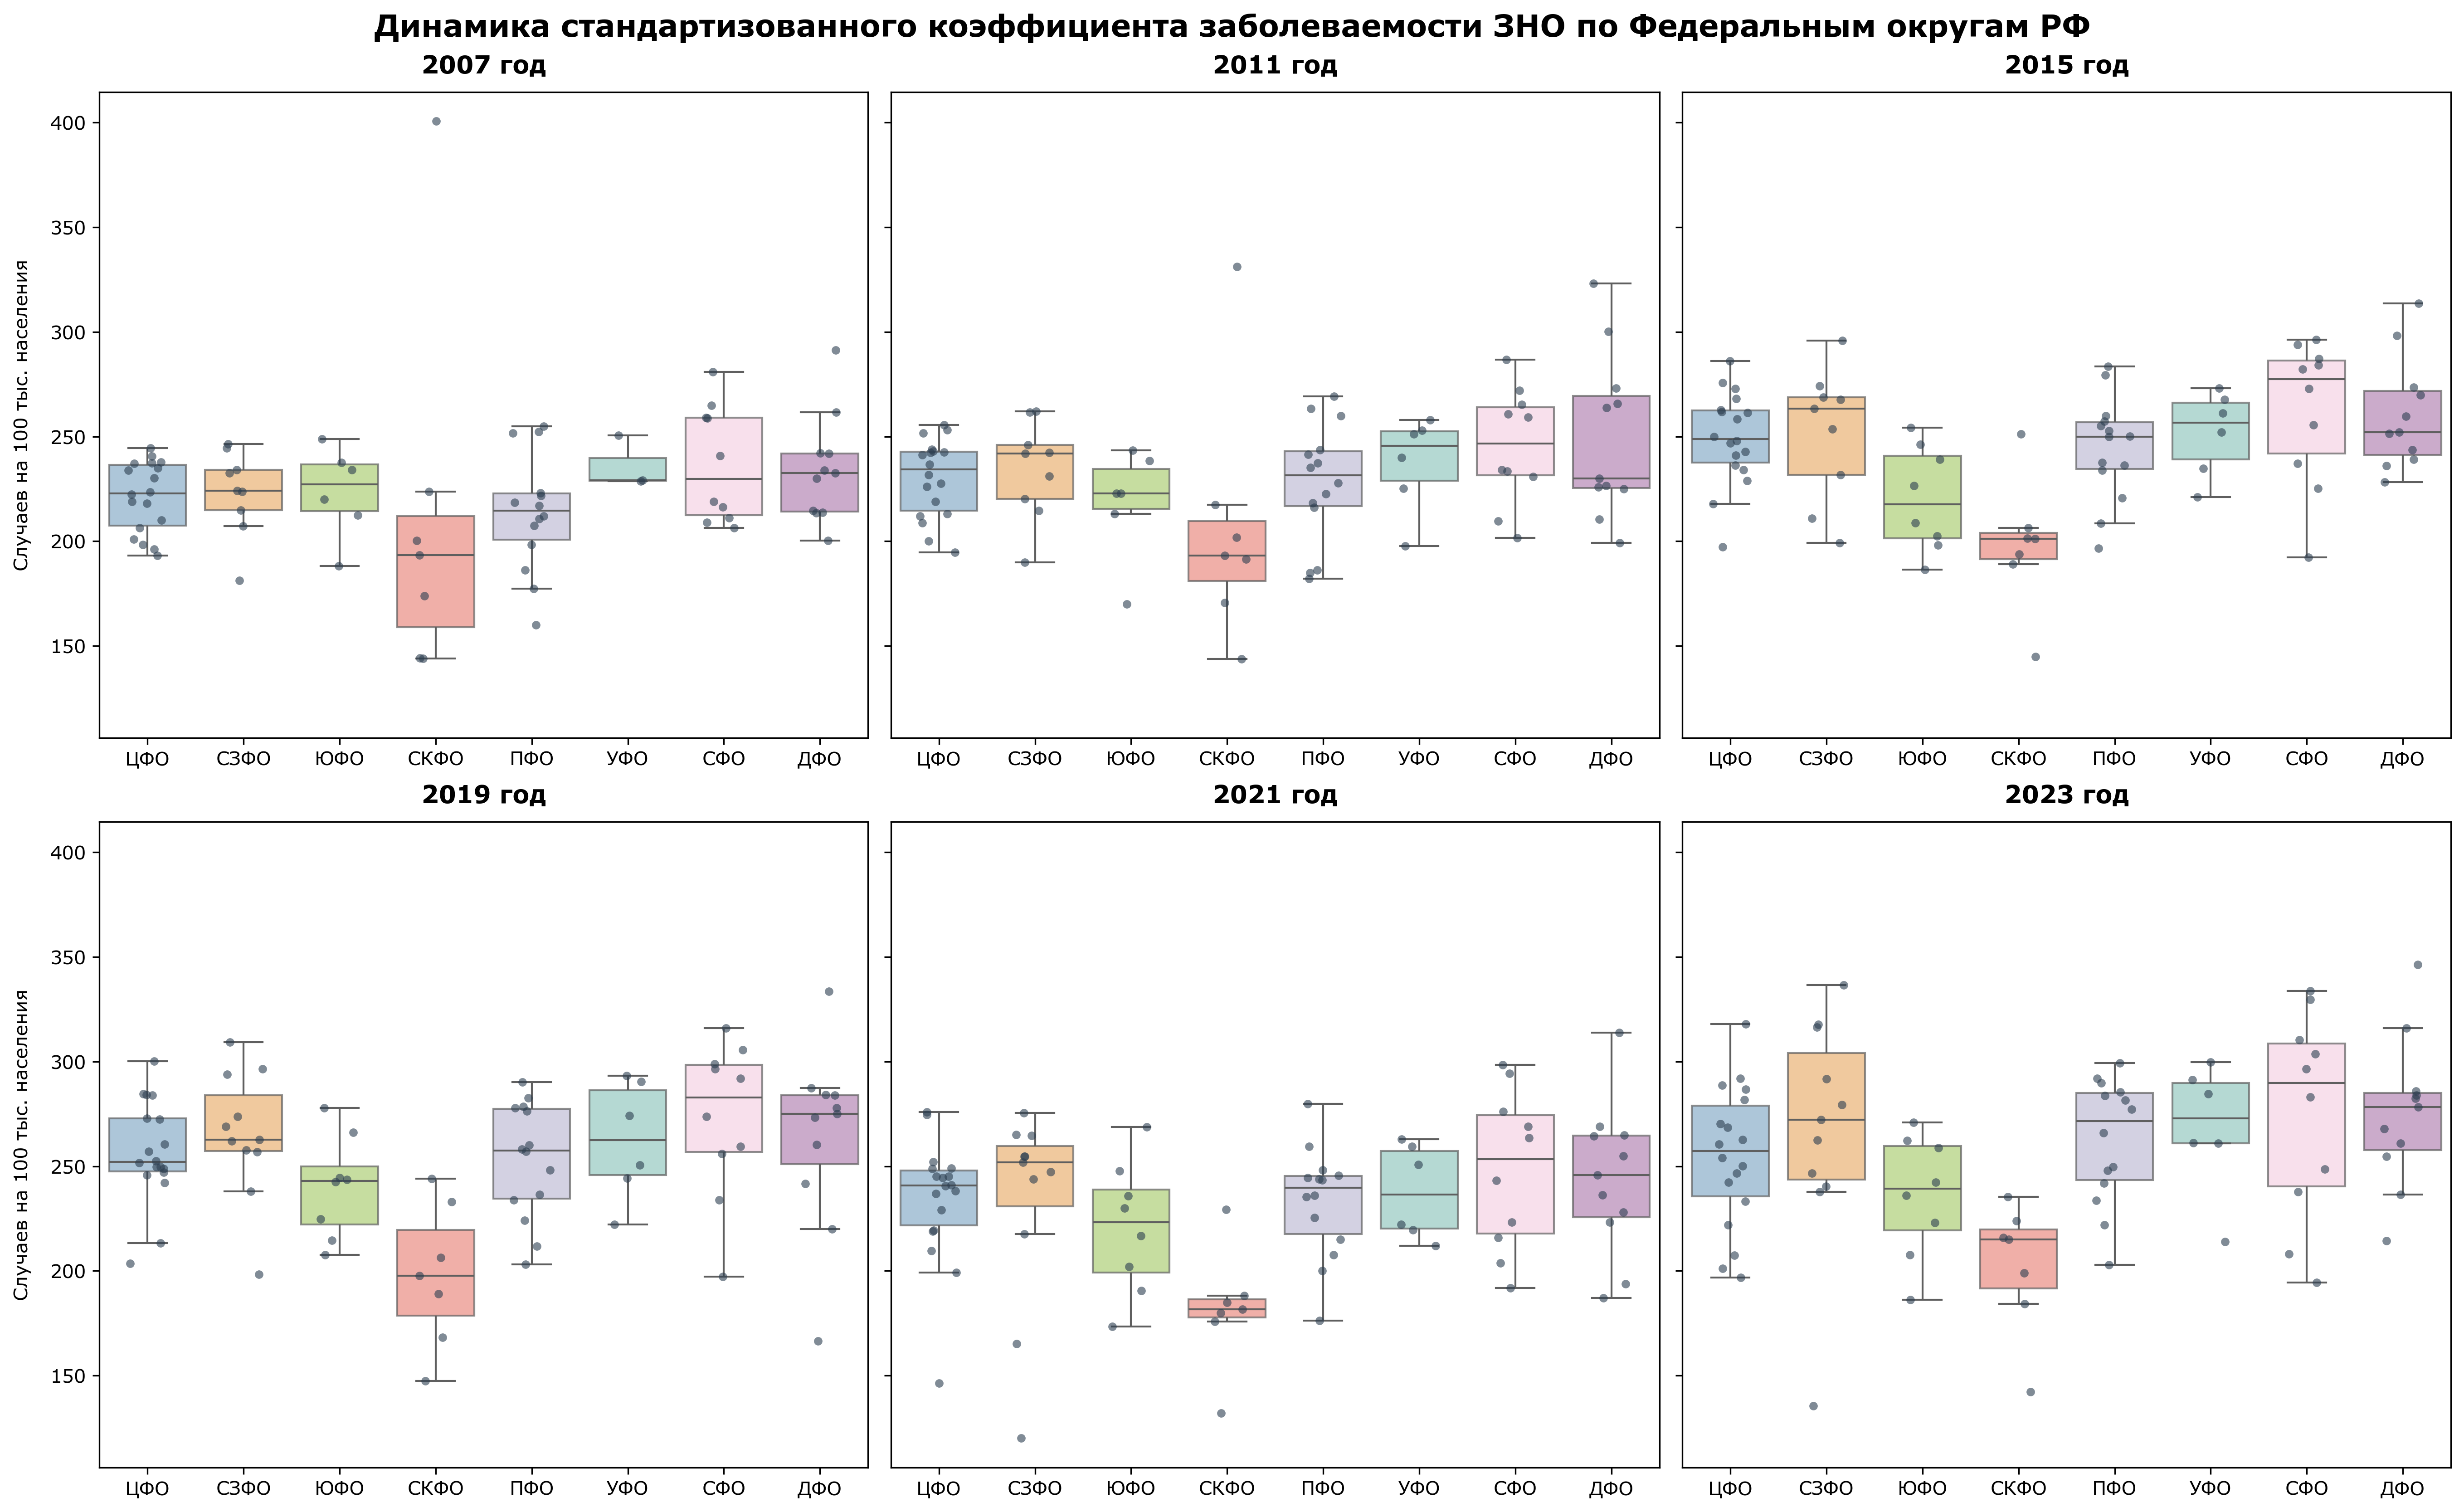

In [232]:
#строим динамику стандартизированной заболеваемости по фо
build_boxplot_dynamics("Стандартизованный коэффициент заболеваемости",
                       "Случаев на 100 тыс. населения",
                       "Динамика стандартизованного коэффициента заболеваемости ЗНО по Федеральным округам РФ")

###  Динамика стандартизированного коэффициента заболеваемости по ФО
Анализ динамики стандартизованного коэффициента заболеваемости по федеральным округам с 2007 по 2023 год показывает чёткий восходящий тренд. Если в 2007 году медианы округов концентрировались в диапазоне 200–240 случаев на 100 тыс. населения, то к 2023 году они сместились к отметке 250–290. При этом рост сопровождается устойчивой пространственной дифференциацией.

Географический разрыв между макрорегионами сохраняется на протяжении всего периода. Северо-Кавказский округ (СКФО) стабильно демонстрирует самые низкие показатели в стране — его медиана удерживается ниже 200–220 случаев (а также наибольшие выбросы, что невольно заставляет вспомнить приговорку о Кавказской статистике). Однако помимо статистичесикх особенностей данного региона это обусловлено более низким уровнем медицины и благоприятным климатом (в т.ч. горным). Наибольшие значения показателя имеют Сибирский (СФО), Северо-Западный (СЗФО) и Дальневосточный (ДФО) округа, где выявляемость традиционно выше, а медианные значения к 2023 году достигли 280–290 случаев.

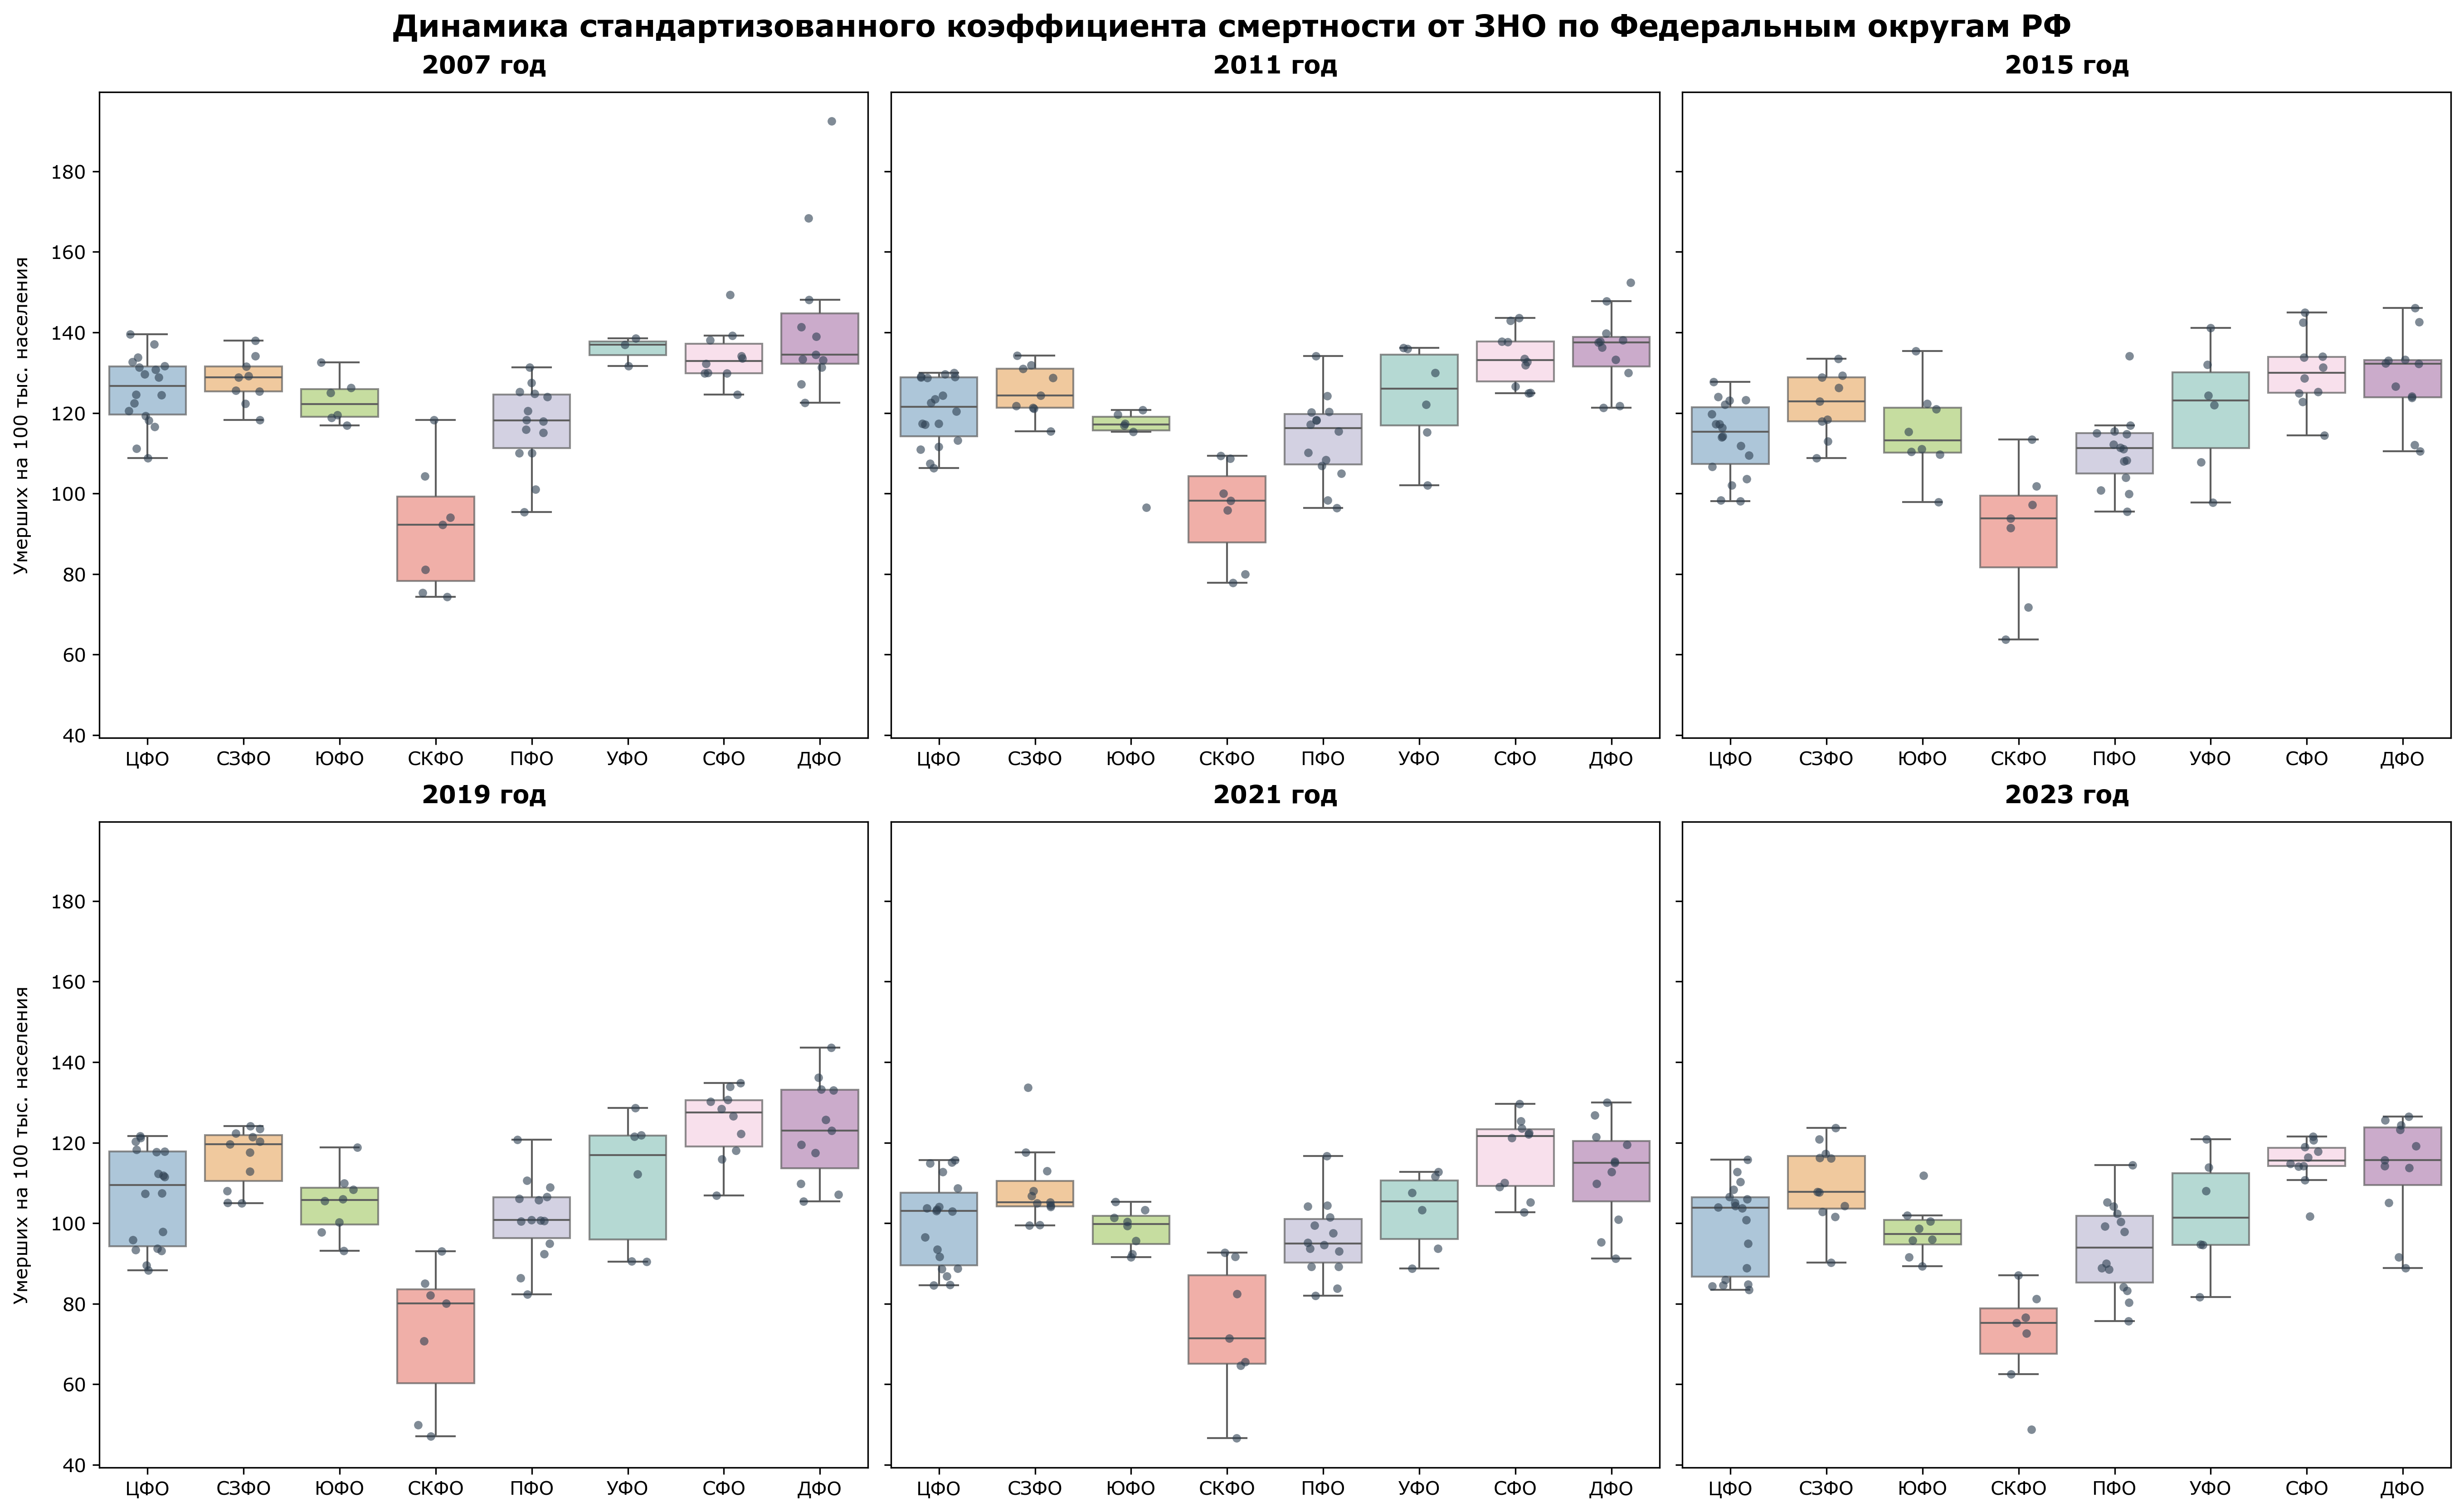

In [233]:
#строим динамику стандартизированной смертности по фо
build_boxplot_dynamics("Стандартизованный коэффициент смертности",
                       "Умерших на 100 тыс. населения",
                       "Динамика стандартизованного коэффициента смертности от ЗНО по Федеральным округам РФ")

###  Динамика стандартизированного коэффициента смертности по ФО
Анализ динамики стандартизованного коэффициента смертности по федеральным округам с 2007 по 2023 год демонстрирует позитивный тренд на общее снижение показателей. Если в 2007 году медианные значения смертности в большинстве округов концентрировались в диапазоне 120–140 умерших на 100 тыс. населения, то к 2023 году они планомерно опустились до отметки 90–115.

При этом полностью сохраняется географическая дифференциация, повторяющаяся за показателями заболеваемости. Важно отметить также сглаживание межрегионального разброса и постепенное исчезновение экстремальных аномалий. Если в 2007 году в ДФО и СФО наблюдались выбивающиеся показатели отдельных регионов (вплоть до 170–190 случаев смертности), то к 2023 году размах заметно сузился. Это указывает на то, что устойчивое падение смертности достигается за счёт выравнивания качества онкологической помощи и стандартизации терапевтических протоколов по всей стране.

In [12]:
#вспомогательная функция для создания бивариативных карт
def assign_bivariate_colors(df, var_x, var_y, palette):
    """Делает легенду для бивариативной карты по двум переменным
    
    Params:
    
    df -- исходный датафрейм.
    var_x --  параметр по Ox palette
    var_y -- колонка по Oy palette
    palette -- двумерный массив размером 3x3 с HEX-кодами цветов
        
    Return
    Копия датафрейма с добавленным столбцом "bi_color"
    """
    df_res = df.copy()
    
    #разбиваем каждую переменную на 3 равные группы по квантилям (0, 1, 2)
    df_res["x_bin"] = pd.qcut(df_res[var_x], q=3, labels=[0, 1, 2], duplicates="drop").astype(int)
    df_res["y_bin"] = pd.qcut(df_res[var_y], q=3, labels=[0, 1, 2], duplicates="drop").astype(int)
    
    #присваиваем цвет из матрицы palette[y_bin, x_bin]
    df_res["bi_color"] = df_res.apply(lambda row: palette[row["y_bin"]][row["x_bin"]], axis=1)
    
    #убираем временные столбцы
    df_res = df_res.drop(columns=["x_bin", "y_bin"])
    
    return df_res

#функция для создания бивариативных карт на основе датафрейма
def bivariant_map(df, x, y, palette, ax, title):
    """Строит бивариантную карту по заданным переменным на основе датафрейма

    Params:
        df -- датафрейм на основе которого 
        x -- название параметра по Ox palette
        y -- название параметра по Oy palette
        palette -- двумерный массив размером 3x3 с HEX-кодами цветов
        ax -- оси для постороения
        title -- название для графика
    """
    df_biv_map = assign_bivariate_colors(df, x, y, palette)

    #мерджим с протсранственными данными
    gdf_biv = gdf_russia.merge(df_biv_map, left_on="region", right_on="join_name", how="left")
    
    #бивариативная карта
    gdf_biv.plot(color=gdf_biv["bi_color"].fillna("#ffffff"), ax=ax, edgecolor="black", linewidth=0.2)
    ax.set_title(title, pad=8)
    ax.axis("off")

def plot_bivariant_legend(palette, ax, x0, y0, w, h, x_label, y_label):
    """Делает легенду к бивариаивной карте

    Params:
        palette -- двумерный массив размером 3x3 с HEX-кодами цветов
        ax -- оси, в которые добавляем легенду
        x0 -- координата легенды по х
        y0 -- координата легенды по y
        w -- ширина легенды
        h -- высота легенды
        x_label -- подпись по оси х
        y_label -- подпись по оси y
    """
    #теперь отдельно к ней легенду через доп. оси, т.е. доп миниграфик по сути
    ax_legend = ax.inset_axes([x0, y0, w, h])
    ax_legend.grid(False) #убираем сетку по умолчанию
    rgb_matrix = np.array([[to_rgb(color) for color in row] for row in palette]) #переводим hex в rgb
    ax_legend.imshow(rgb_matrix, origin="lower") #lower ставит минимальный возраст вниз
    ax_legend.set_xticks([])
    ax_legend.set_yticks([])
    ax_legend.set_xlabel(x_label, fontsize=8, labelpad=4, fontweight="bold")
    ax_legend.set_ylabel(y_label, fontsize=8, labelpad=4, fontweight="bold")

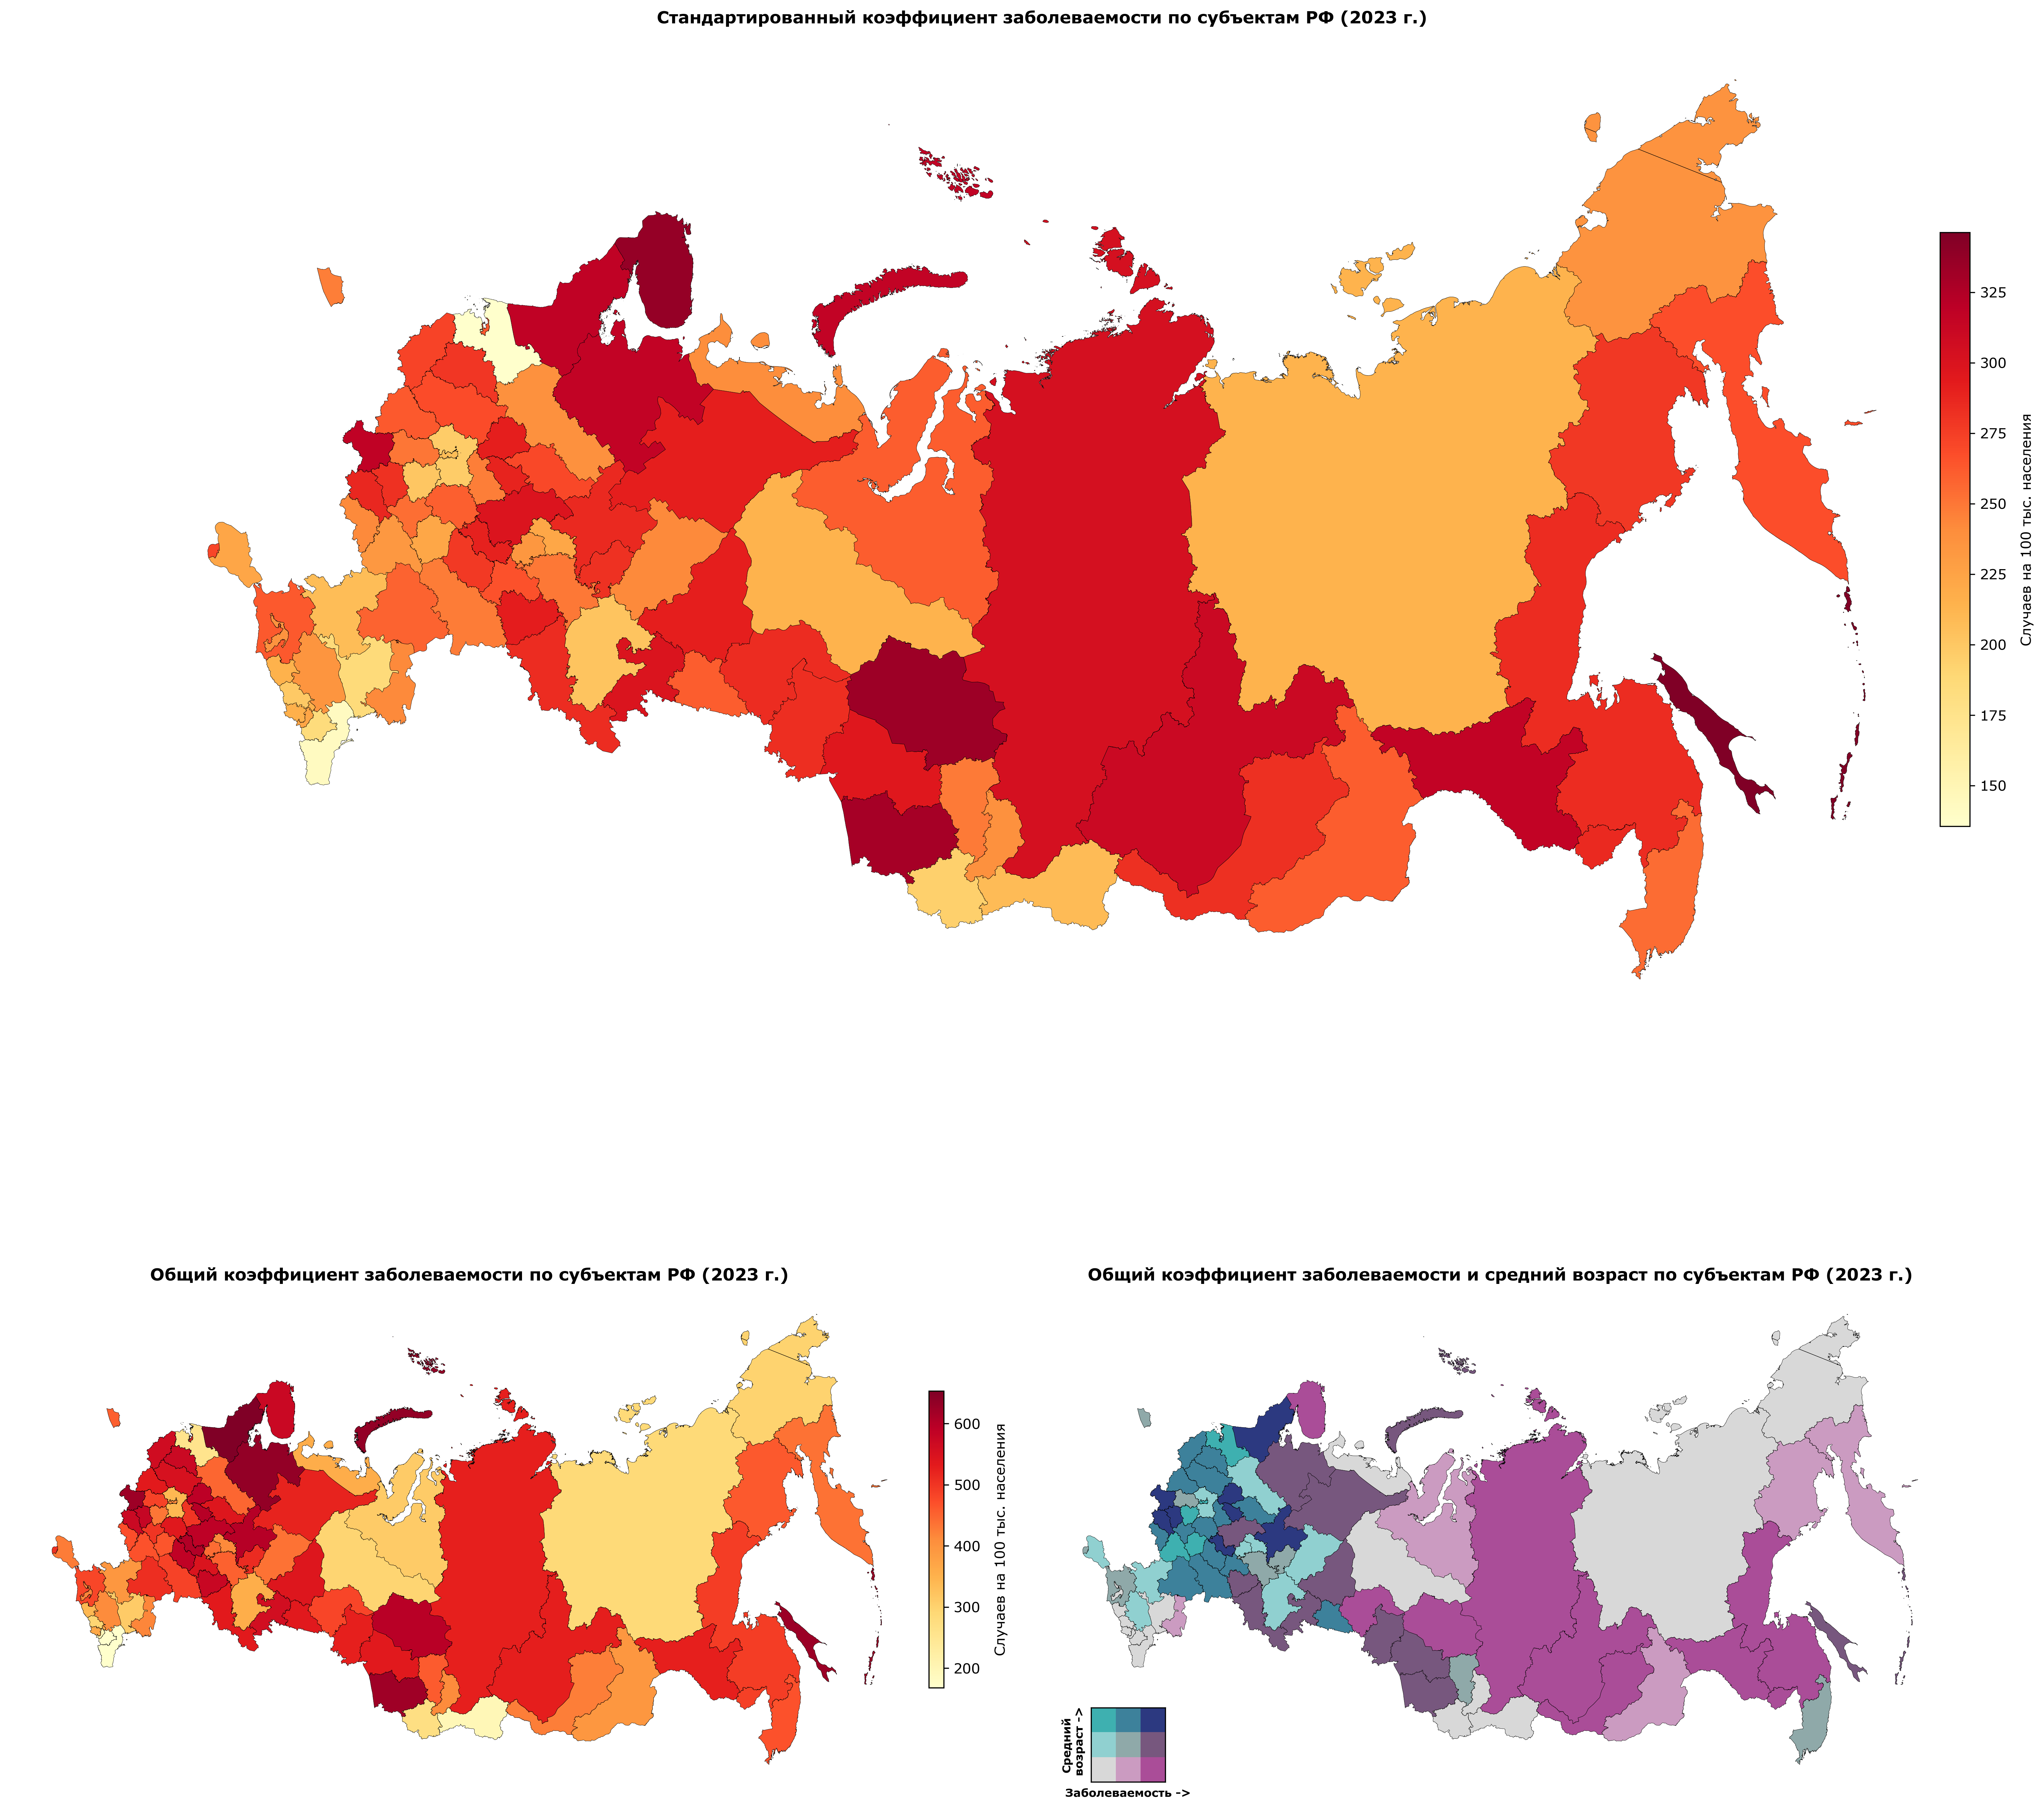

In [14]:
#берем срез по регионам на 2023
df_std_2023 = get_oncology_slice(indicator="Стандартизованный коэффициент заболеваемости", year=2023, object_level="Регион")
df_crude_2023 = get_oncology_slice(indicator="Общий коэффициент заболеваемости", year=2023, object_level="Регион")

#вытаскиваем средний возраст населения
df_mean_age_2023 = df_demo[(df_demo["indicator_code"] == "Y477010007") & (df_demo["year"] == 2023) & 
    (df_demo["subsection"] == "Все население: мужчины и женщины")].copy()

#соединяем демографию и общий коэффициент заболеваемости
df_biv_prep = df_std_2023.merge(
    df_mean_age_2023[["join_name", "indicator_value"]], 
    on="join_name", 
    how="inner",
    suffixes=("_morb", "_age")
)

#делаем бивариантную палитру 3х3 (общая заболеваемость X × средний возраст Y) 
palette = np.array(
    [["#d8d8d8", "#cb9bc1", "#aa4d98"],
    ["#90d0d0", "#8fa9a9", "#77577e"], 
    ["#3eb0b0", "#3d819b", "#2c3980"]]
)

#мерджим стандартизированную заболеваемость с протсранственными данными
gdf_std = gdf_russia.merge(df_std_2023, left_on="region", right_on="join_name", how="left")
gdf_crude = gdf_russia.merge(df_crude_2023, left_on="region", right_on="join_name", how="left")

#строим карты
fig = plt.figure(figsize=(20, 20), constrained_layout=True)
gs = fig.add_gridspec(2, 2) #внутренняя сетка для настроек сабплотов разных размеров

ax = [
    fig.add_subplot(gs[1, 0]),  #ax[0] -- общая заболеваемость
    fig.add_subplot(gs[1, 1]),  #ax[1] -- бивариант
    fig.add_subplot(gs[0, :])   #ax[2] -- стандартизованная заболеваемость
]

#стандартизированный коэффициент заболеваемости
gdf_std.plot(column="indicator_value", cmap="YlOrRd", legend=True, ax=ax[2],edgecolor="black",linewidth=0.2,
             legend_kwds={"shrink": 0.6, "pad": -0.01, "label": "Случаев на 100 тыс. населения"})
ax[2].set_title("Стандартированный коэффициент заболеваемости по субъектам РФ (2023 г.)", pad=8)
ax[2].axis("off")

#общий коэффициент заболеваемости
gdf_crude.plot(column="indicator_value", cmap="YlOrRd", legend=True, ax=ax[0],edgecolor="black",linewidth=0.2,
             legend_kwds={"shrink": 0.3, "pad": -0.05, "label": "Случаев на 100 тыс. населения"})
ax[0].set_title("Общий коэффициент заболеваемости по субъектам РФ (2023 г.)", pad=8)
ax[0].axis("off")

#бивариантная карта
bivariant_map(df_biv_prep, "indicator_value_morb", "indicator_value_age", palette, ax[1], 
             "Общий коэффициент заболеваемости и средний возраст по субъектам РФ (2023 г.)")

#теперь отдельно к ней легенду через доп. оси, т.е. доп миниграфик по сути
plot_bivariant_legend(palette, ax[1], 0.02, 0.01, 0.15, 0.15, "Заболеваемость ->", "Средний\n  возраст ->")
                      
plt.show()

### Пространственное распредление показателей заболеваемости и влияние вощратсной структуры
Сопоставление карт общего и стандартизованного коэффициентов заболеваемости за 2023 год наглядно иллюстрирует, как демографическая структура искажает первичную географическую картину. На карте общего коэффициента наблюдается концентрация максимальных показателей (свыше 500–600 случаев на 100 тыс. населения) в демографически старых субъектах Европейской части России, Урала и Сибири. Бивариантная карта дополнительно подтверждает эту зависимость.   
Переход к стандартизованному коэффициенту меняет пространственную структуру заболеваемости. Устранение возрастного фактора сглаживает доминирование Центральной России и высвечивает реальные эпидемиологические неблагополучия: очаги высокой заболеваемости смещаются в Сибирь, на Дальний Восток и Северо-Запад (Сахалин, Красноярский край, Карелия и Мурманская область). Высокая первичная заболеваемость в этих макрорегионах обусловлена не старением населения, а локальными факторами — качеством окружающей среды, образом жизни и эффективностью региональных программ онкоскрининга. 

In [236]:
def build_correlation(ax, df_corr_data, var_1, var_2, x_label, y_label, title):
    """Показывает корреляцию между двумя парметрами
        Params:
        ax -- оси для построения графика с отображением корреляции
        df_corr_data -- датафрейм с показателями, между которыми смотрим корреляцию
        var_1 -- название первой переменной (Ох)
        var_2 -- название второй переменной (Ох)
        x_label -- подпись оси х
        y_label -- подпись оси у
        title -- название графика
    """
    
    #рассчитаем коэффциент корреляции Спирмана и p_val
    x_val = df_corr_data["indicator_value_age"]
    y_val = df_corr_data.loc[x_val.index, "indicator_value_morb"]
    r_spearman, p_val = stats.spearmanr(x_val, y_val)

    #строим график
    sns.regplot(data=df_corr_data, x=var_1, y=var_2,ax=ax, color="#2c3e50")
    ax.set_title(f"{title}\n(r = {r_spearman:.2f}, p = {p_val:.4f})")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

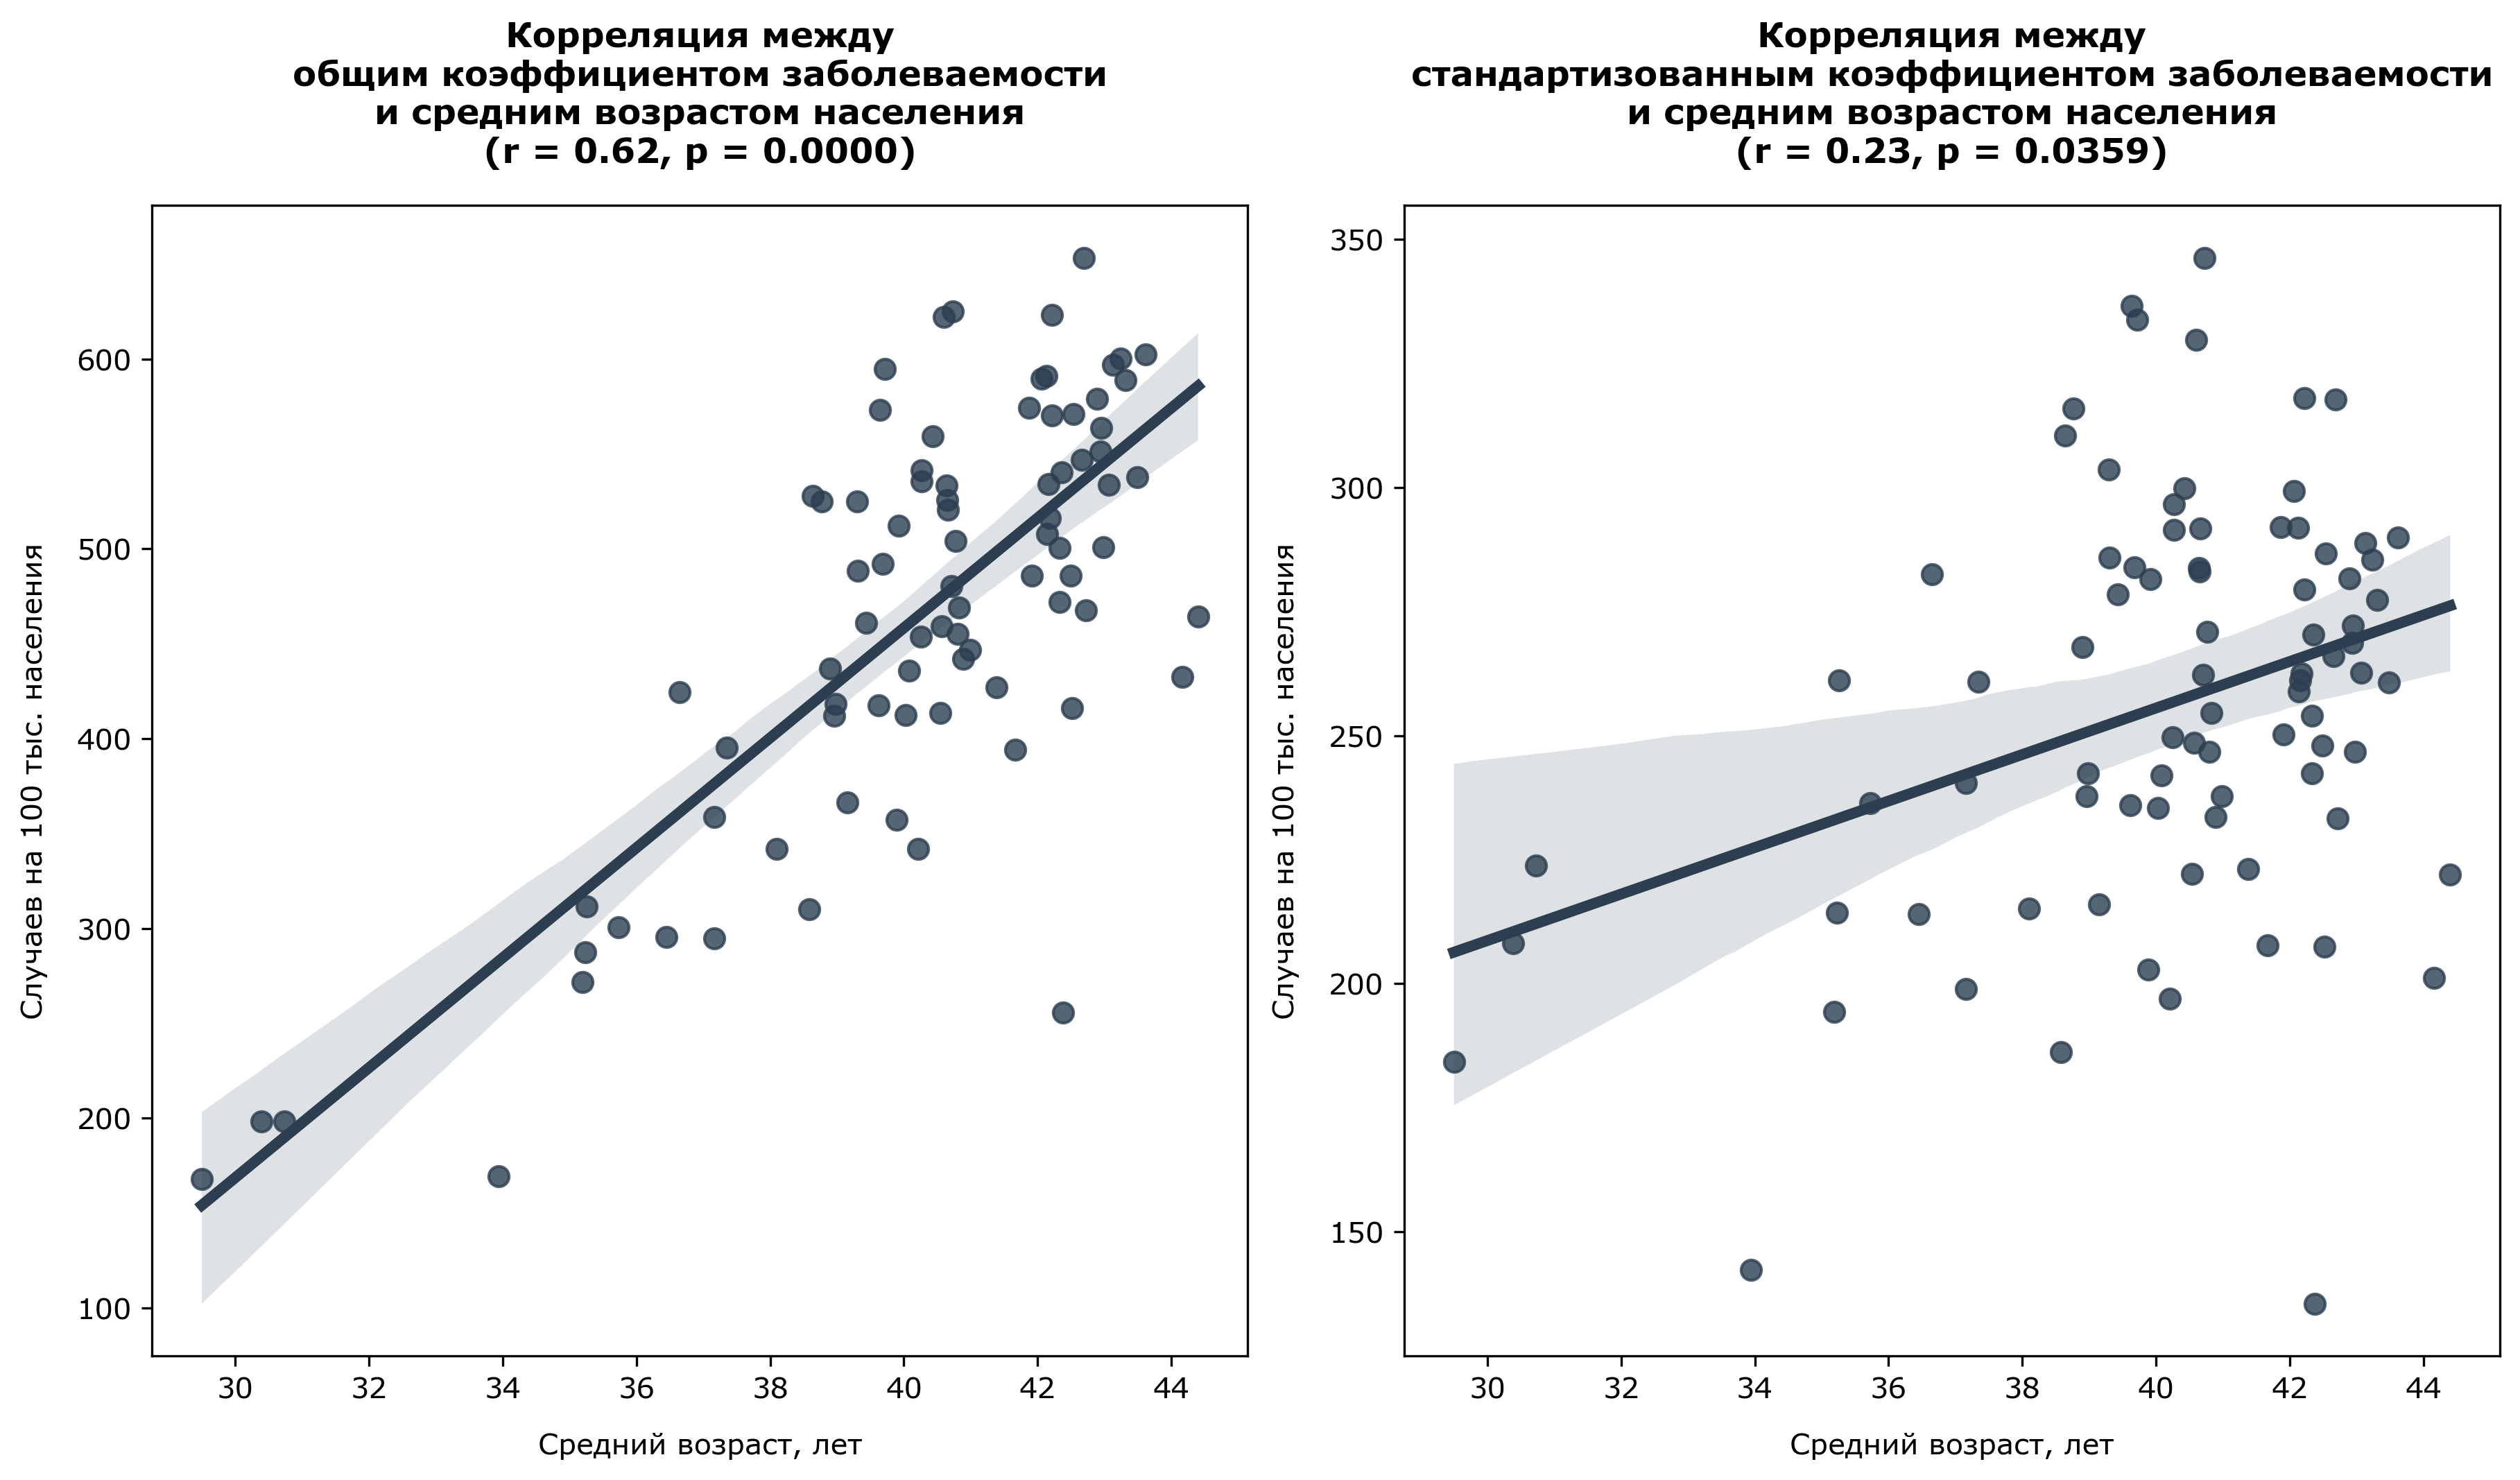

In [237]:
#посмотрим насколько общий коэффициент коррелирует со средним возрастом, а стандартизованный нет
df_crude_corr_data = df_crude_2023.merge(df_mean_age_2023, left_on="object_name", right_on="object_name", how="inner", suffixes=("_morb", "_age"))
indices_to_drop = df_сrude_corr_data[df_сrude_corr_data["indicator_value_age"] < 0].index
df_crude_corr_data = df_crude_corr_data.drop(index=indices_to_drop)

df_std_corr_data = df_std_2023.merge(df_mean_age_2023, left_on="object_name", right_on="object_name", how="inner", suffixes=("_morb", "_age"))
indices_to_drop = df_std_corr_data[df_std_corr_data["indicator_value_age"] < 0].index
df_std_corr_data = df_std_corr_data.drop(index=indices_to_drop)

#расчитываем и визуализируем корреляцию
fig, ax = plt.subplots(1, 2, figsize=(12, 7), constrained_layout=True)
build_correlation(ax[0], df_crude_corr_data, "indicator_value_age", "indicator_value_morb", 
                  "Средний возраст, лет", "Случаев на 100 тыс. населения",
                  "Корреляция между\nобщим коэффициентом заболеваемости\nи средним возрастом населения")

build_correlation(ax[1], df_std_corr_data, "indicator_value_age", "indicator_value_morb", 
                  "Средний возраст, лет", "Случаев на 100 тыс. населения",
                  "Корреляция между\nстандартизованным коэффициентом заболеваемости\nи средним возрастом населения")
plt.show()

Сравнительный корреляционный анализ подтвержадет определяющее влияние демографического фактора: между общим коэффициентом заболеваемости и средним возрастом населения наблюдается сильная положительная связь ($r = 0.62, p = 0.0000$), подтверждающая, что высокие показатели общей заболеваемости в регионах напрямую обусловлены старением их населения. 
В свою очередь, переход к стандартизованному коэффициенту существенно ослабляет эту зависимость ($r = 0.23, p = 0.0359$), что подтверждает методологическую необходимость стандартизации — она успешно очищает данные от искажающего эффекта возрастной структуры и позволяют объективно сравнивать реальную онкологическую обстановку между субъектами РФ (обусловленную именно уровнем медицины, качеством помощи и тд)

In [238]:
#Вспомогательная функция для расчёта MIR по регионам
def calculate_mir(year="all", sex="Оба пола", age="Всего", nosology="Все злокачественные новообразования"):
    """Расчет индекса MIR (Mortality-to-Incidence Ratio = Смертность / Заболеваемость)
        Params:
        year -- временной диапазон, может принимать значения типа:
        - int за один конкретный год (например, 2023)
        - list/tuple/range: за диапазон годов (например, [2020, 2021, 2022] или range(2007, 2024))
        - all (string): за все имеющиеся года без фильтрации по времени -- значение по умолчанию
        sex -- пол 
        sex -- пол (Оба пола, Женщины, Мужчины), по умолчанию оба пола
        age -- возрастная группа (0-14 лет, 0-17 лет, Всего), по умолчанию всего
        nosology_name -- разновидность заболевания (полный список представлен в описании данных), по умолчанию аггрегированный показатель
                    при значении all (значением по умолчанию) собирает все категории
    """
    df_morb = get_oncology_slice(
        indicator="Стандартизованный коэффициент заболеваемости",
        year=year,
        sex=sex,
        age=age,
        nosology_name=nosology,
        object_level="Регион"
    )
    
    df_mort = get_oncology_slice(
        indicator="Стандартизованный коэффициент смертности",
        year=year,
        sex=sex,
        age=age,
        nosology_name=nosology,
        object_level="Регион"
    )
    
    merged = pd.merge(
        df_morb[["join_name", "sex", "indicator_value"]],
        df_mort[["join_name", "sex", "indicator_value"]],
        on=["join_name", "sex"],
        how="inner",
        suffixes=("_morb", "_mort")
    )
    
    merged["MIR"] = merged["indicator_value_mort"]/merged["indicator_value_morb"]
    
    return merged

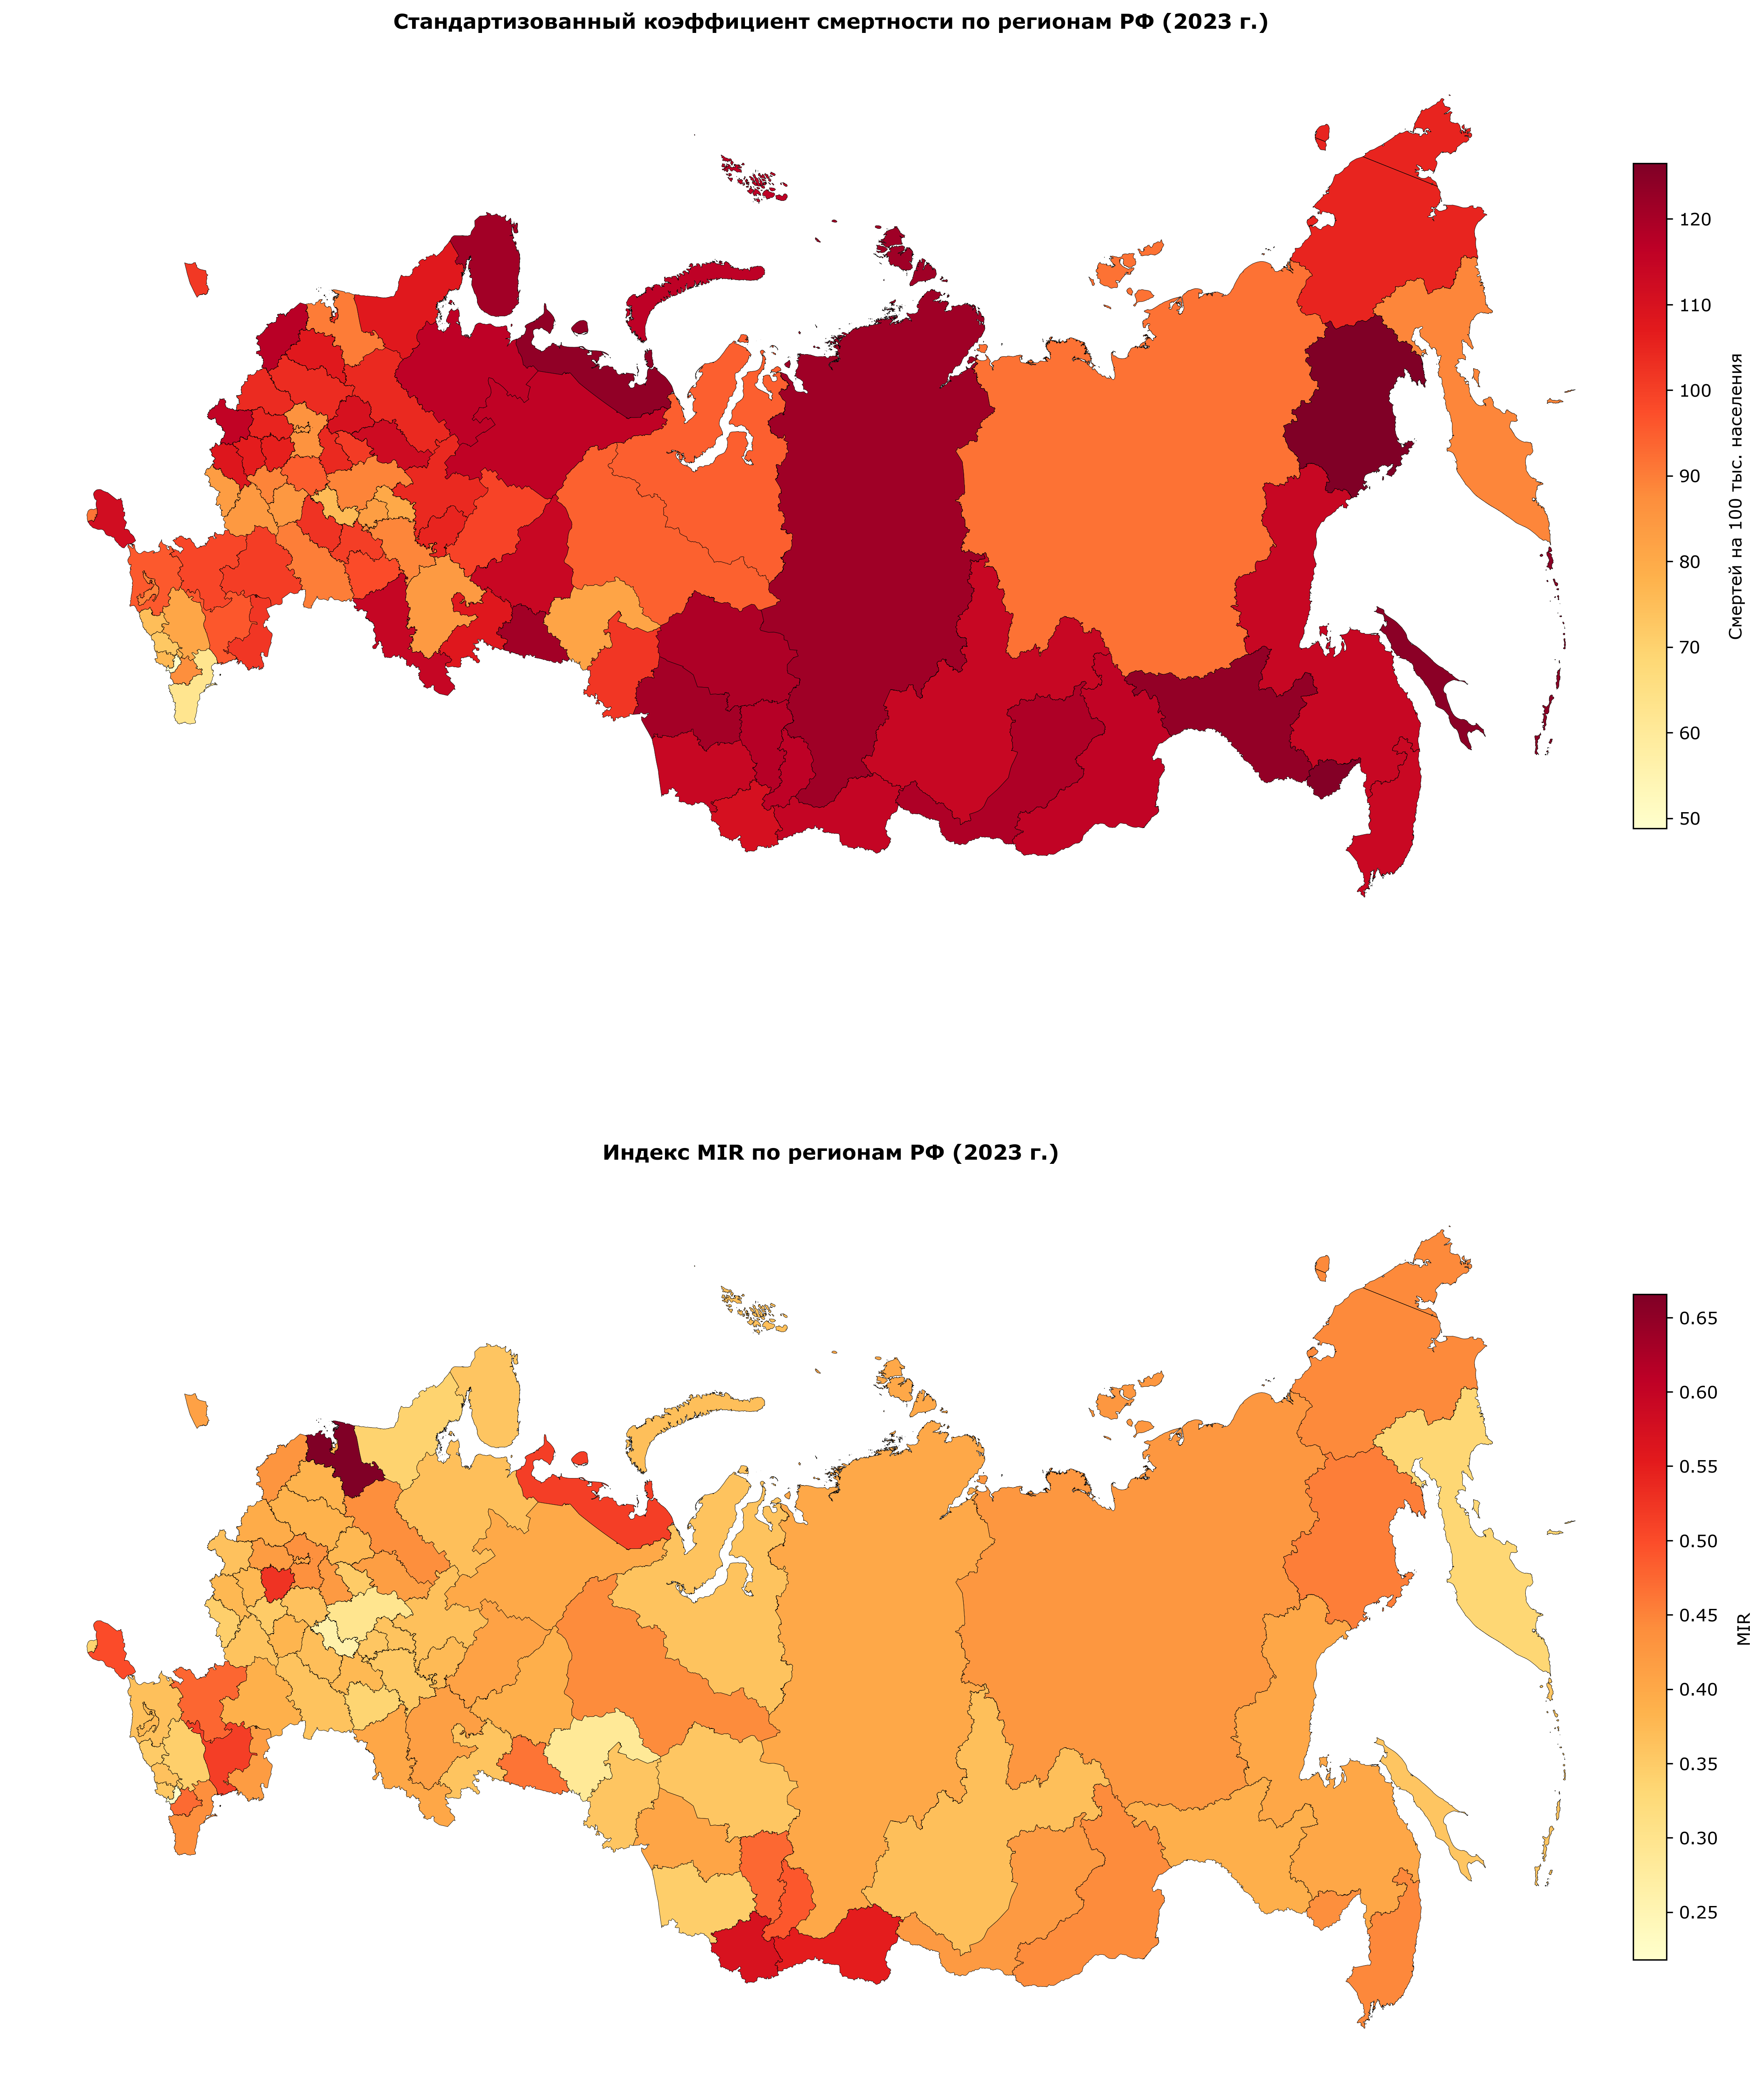

In [239]:
df_mir_reg_2023 = calculate_mir(year=2023)

gdf_mir_2023 = gdf_russia.merge(df_mir_reg_2023, left_on="region", right_on="join_name", how="left")

df_std_mort_2023 = get_oncology_slice(indicator="Стандартизованный коэффициент смертности", year=2023, object_level="Регион")
gdf_std_mort_2023 = gdf_russia.merge(df_std_mort_2023, left_on="region", right_on="join_name", how="left")

fig, ax = plt.subplots(2, 1, figsize=(14, 18), constrained_layout=True)

gdf_std_mort_2023.plot(column="indicator_value", cmap="YlOrRd", legend=True, ax=ax[0], edgecolor="black",linewidth=0.2,
         legend_kwds={"shrink": 0.6, "pad": -0.01, "label": "Смертей на 100 тыс. населения"})
ax[0].set_title("Стандартизованный коэффициент смертности по регионам РФ (2023 г.)")
ax[0].axis("off")

gdf_mir_2023.plot(column="MIR", cmap="YlOrRd", legend=True, ax=ax[1], edgecolor="black",linewidth=0.2,
         legend_kwds={"shrink": 0.6, "pad": -0.01, "label": "MIR"})
ax[1].set_title("Индекс MIR по регионам РФ (2023 г.)")
ax[1].axis("off")

plt.show()

### Пространственное распредление показателей смертности
На карте стандартизованной смертности наибольшие показатели (свыше 110–120 умерших на 100 тыс. населения) концентрируются в субъектах Сибири, Дальнего Востока и Европейского Севера (Карелия, Архангельская область), тогда как наименьшие значения (менее 60–70) стабильно демонстрируют республики Северного Кавказа.   
Индекс MIR, рассчитываемый как отношение смертности к заболеваемости, служит ключевым индикатором эффективности раннего выявления и лечения. Высокие значения MIR (выше 0.50–0.60, выделенные тёмно-красным цветом в Республике Тыва, Карелии и отдельных регионах ДФО) свидетельствуют о высокой доле запущенных случаев и низкой выживаемости больных. Напротив, минимальные значения MIR (менее 0.30–0.35, светлые оттенки) в мегаполисах (Москва, Санкт-Петербург) и развитых субъектах ЦФО и ПФО подтверждают высокую результативность онкоскринингов и доступность современной терапии. Сюрпризом для меня стали наивысшие значения этого показателя в Ленинградской обалсти, которым при беглом поиске объяснения натйи не удалось.

<Figure size 3600x1800 with 0 Axes>

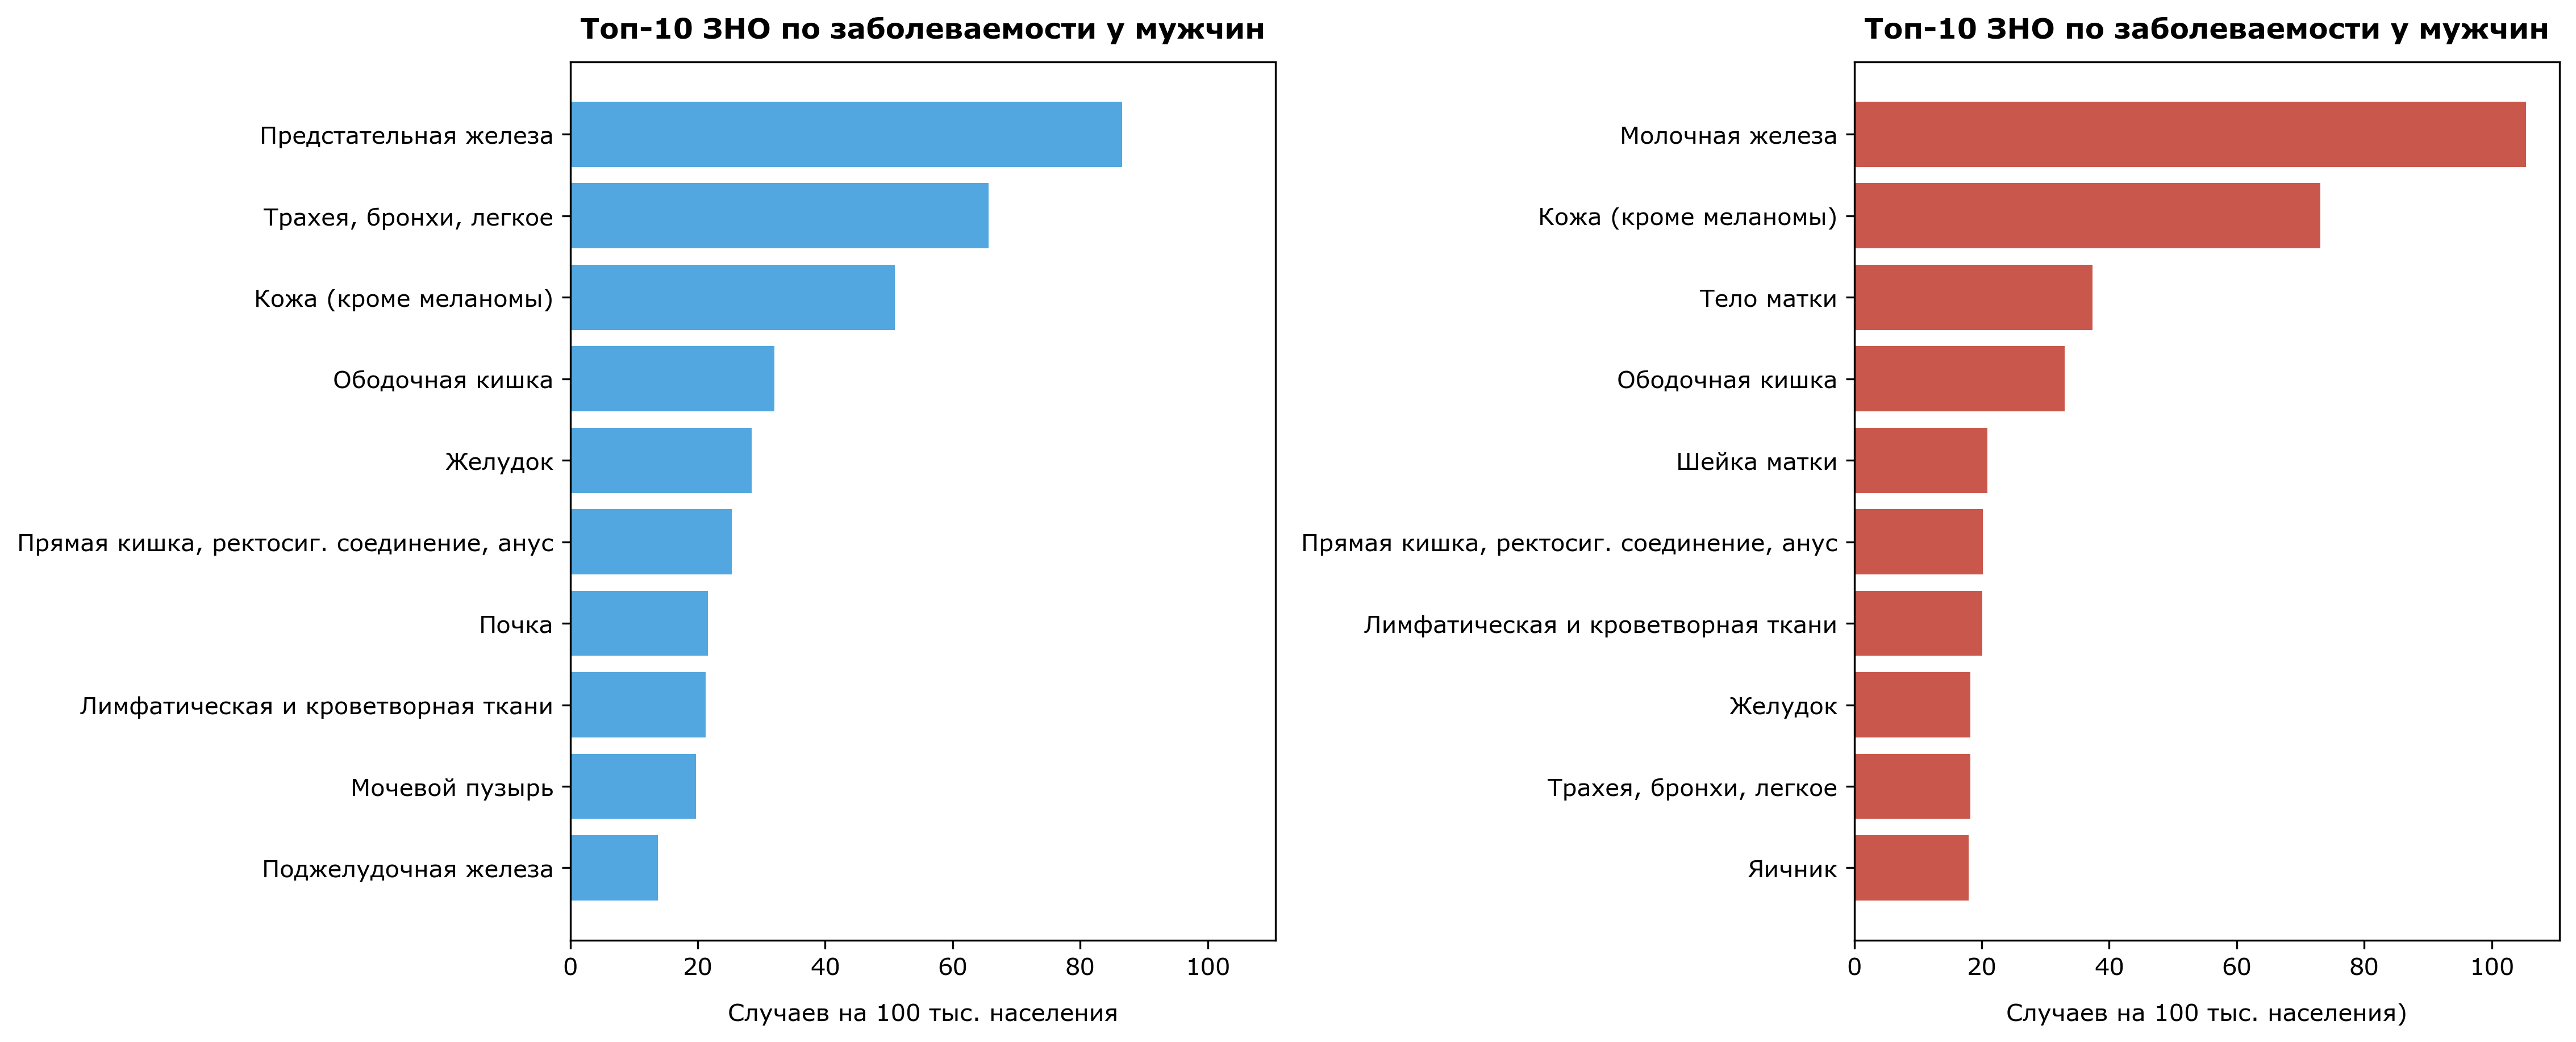

In [240]:
#делаем срезы по общему коэффициенту заболеваемости по полу
df_crude_morb_2023_male = get_oncology_slice(
    indicator="Общий коэффициент заболеваемости",
    year=2023,
    sex="Мужчины",
    nosology_name="all",
    object_level="Страна"
)

df_crude_morb_2023_fem = get_oncology_slice(
    indicator="Общий коэффициент заболеваемости",
    year=2023,
    sex="Женщины",
    nosology_name="all",
    object_level="Страна"
)

#исключаем агрегированную категорию
df_crude_morb_2023_male = df_crude_morb_2023_male[df_crude_morb_2023_male["nosology_name"] != "Все злокачественные новообразования"]
df_crude_morb_2023_fem = df_crude_morb_2023_fem[df_crude_morb_2023_fem["nosology_name"] != "Все злокачественные новообразования"]

#выбираем ЗНО с наибльшим коэффицентом заболеваемости
top10_male = df_crude_morb_2023_male.sort_values("indicator_value", ascending=True).tail(10)
top10_fem = df_crude_morb_2023_fem.sort_values("indicator_value", ascending=True).tail(10)

#строим барплоты
plt.figure(figsize=(12, 6))
width = 0.38
x = np.arange(10)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, constrained_layout=True)

#мужчины
axes[0].barh(top10_male["nosology_name"], top10_male["indicator_value"], color="#3498db", alpha=0.85)
axes[0].set_title("Топ-10 ЗНО по заболеваемости у мужчин", pad=10)
axes[0].set_xlabel("Случаев на 100 тыс. населения")

#женщины
axes[1].barh(top10_fem["nosology_name"], top10_fem["indicator_value"], color="#c0392b", alpha=0.85)
axes[1].set_title("Топ-10 ЗНО по заболеваемости у мужчин", pad=10)
axes[1].set_xlabel("Случаев на 100 тыс. населения)")

plt.show()

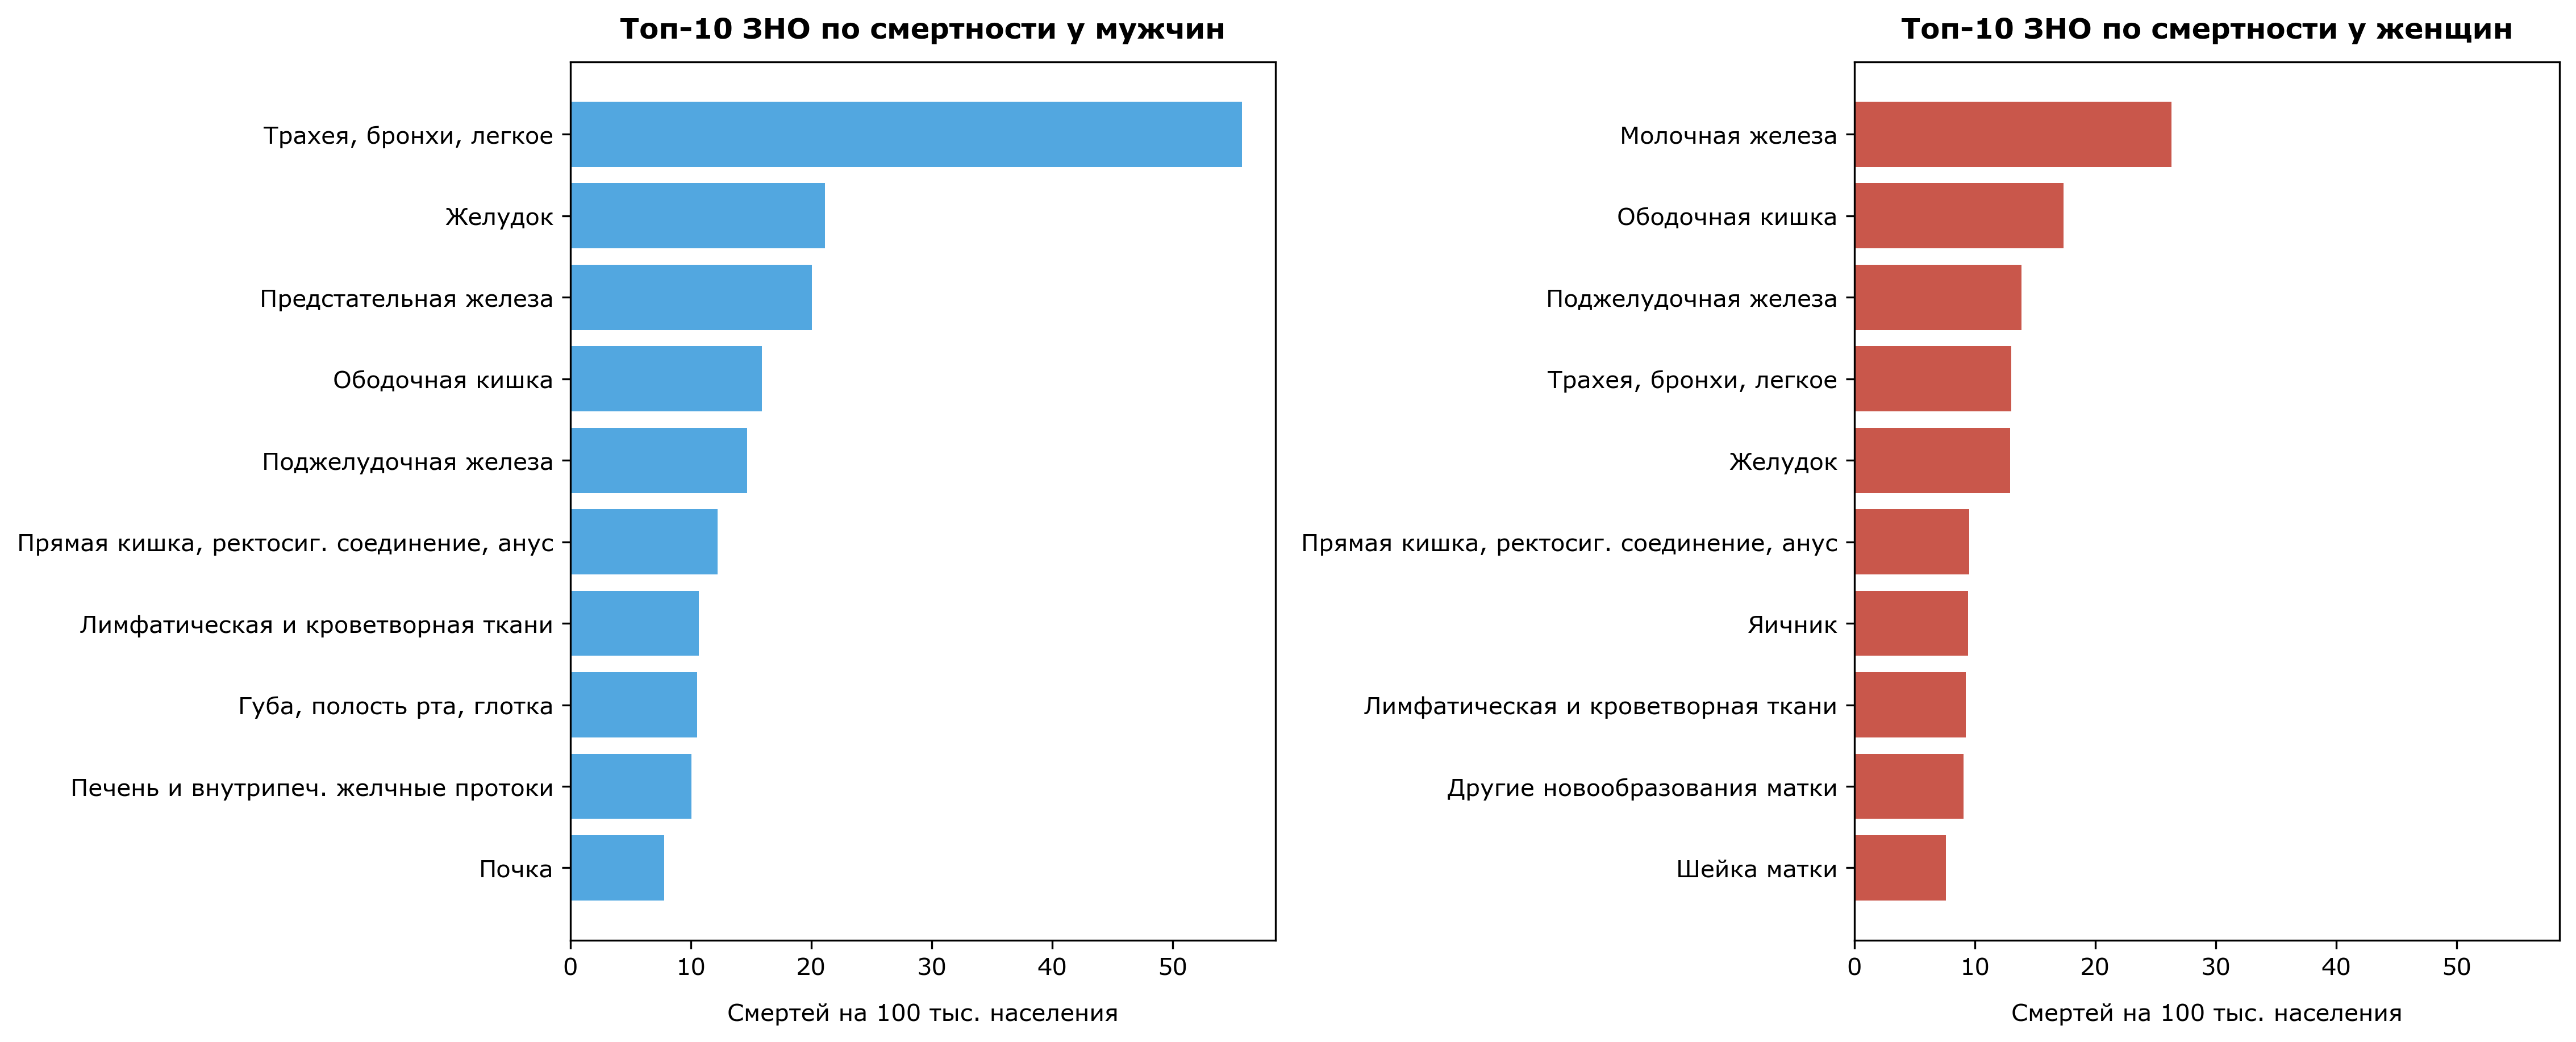

In [241]:
#делаем срезы по общему коэффициенту заболеваемости по полу
df_crude_mort_2023_male = get_oncology_slice(
    indicator="Общий коэффициент смертности",
    year=2023,
    sex="Мужчины",
    nosology_name="all",
    object_level="Страна"
)

df_crude_mort_2023_fem = get_oncology_slice(
    indicator="Общий коэффициент смертности",
    year=2023,
    sex="Женщины",
    nosology_name="all",
    object_level="Страна"
)

#исключаем агрегированную категорию
df_crude_mort_2023_male = df_crude_mort_2023_male[df_crude_mort_2023_male["nosology_name"] != "Все злокачественные новообразования"]
df_crude_mort_2023_fem = df_crude_mort_2023_fem[df_crude_mort_2023_fem["nosology_name"] != "Все злокачественные новообразования"]
df_crude_mort_2023_male = df_crude_mort_2023_male[df_crude_mort_2023_male["nosology_name"] != "Все причины смерти"]
df_crude_mort_2023_fem = df_crude_mort_2023_fem[df_crude_mort_2023_fem["nosology_name"] != "Все причины смерти"]


#выбираем ЗНО с наибльшим коэффицентом смертности
top10_male = df_crude_mort_2023_male.sort_values("indicator_value", ascending=True).tail(10)
top10_fem = df_crude_mort_2023_fem.sort_values("indicator_value", ascending=True).tail(10)

#строим барплоты
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, constrained_layout=True)

#мужчины
axes[0].barh(top10_male["nosology_name"], top10_male["indicator_value"], color="#3498db", alpha=0.85)
axes[0].set_title("Топ-10 ЗНО по смертности у мужчин", pad=10)
axes[0].set_xlabel("Смертей на 100 тыс. населения")

#женщины
axes[1].barh(top10_fem["nosology_name"], top10_fem["indicator_value"], color="#c0392b", alpha=0.85)
axes[1].set_title("Топ-10 ЗНО по смертности у женщин", pad=10)
axes[1].set_xlabel("Смертей на 100 тыс. населения")

plt.show()

### Половозрастные особенности онкологических показателей
Сравнительный анализ топ-10 нозологий демонстрирует выраженную гендерную специфику и существенный разрыв между заболеваемостью и летальностью. По выявляемости у мужчин лидируют рак предстательной железы и органов дыхания, тогда как у женщин доминируют рак молочной железы и кожи. В структуре смертности картина меняется: абсолютным лидером среди мужчин с огромным отрывом становится рак лёгких, бронхов и трахеи, а у женщин наибольшую смертность вызывают рак молочной железы и ободочной кишки. Это наглядно отражает различную агрессивность патологий: частые рак кожи и предстательной железы имеют высокую выживаемость при ранней диагностике, в то время как рак органов дыхания и ЖКТ характеризуются высокой летальностью.

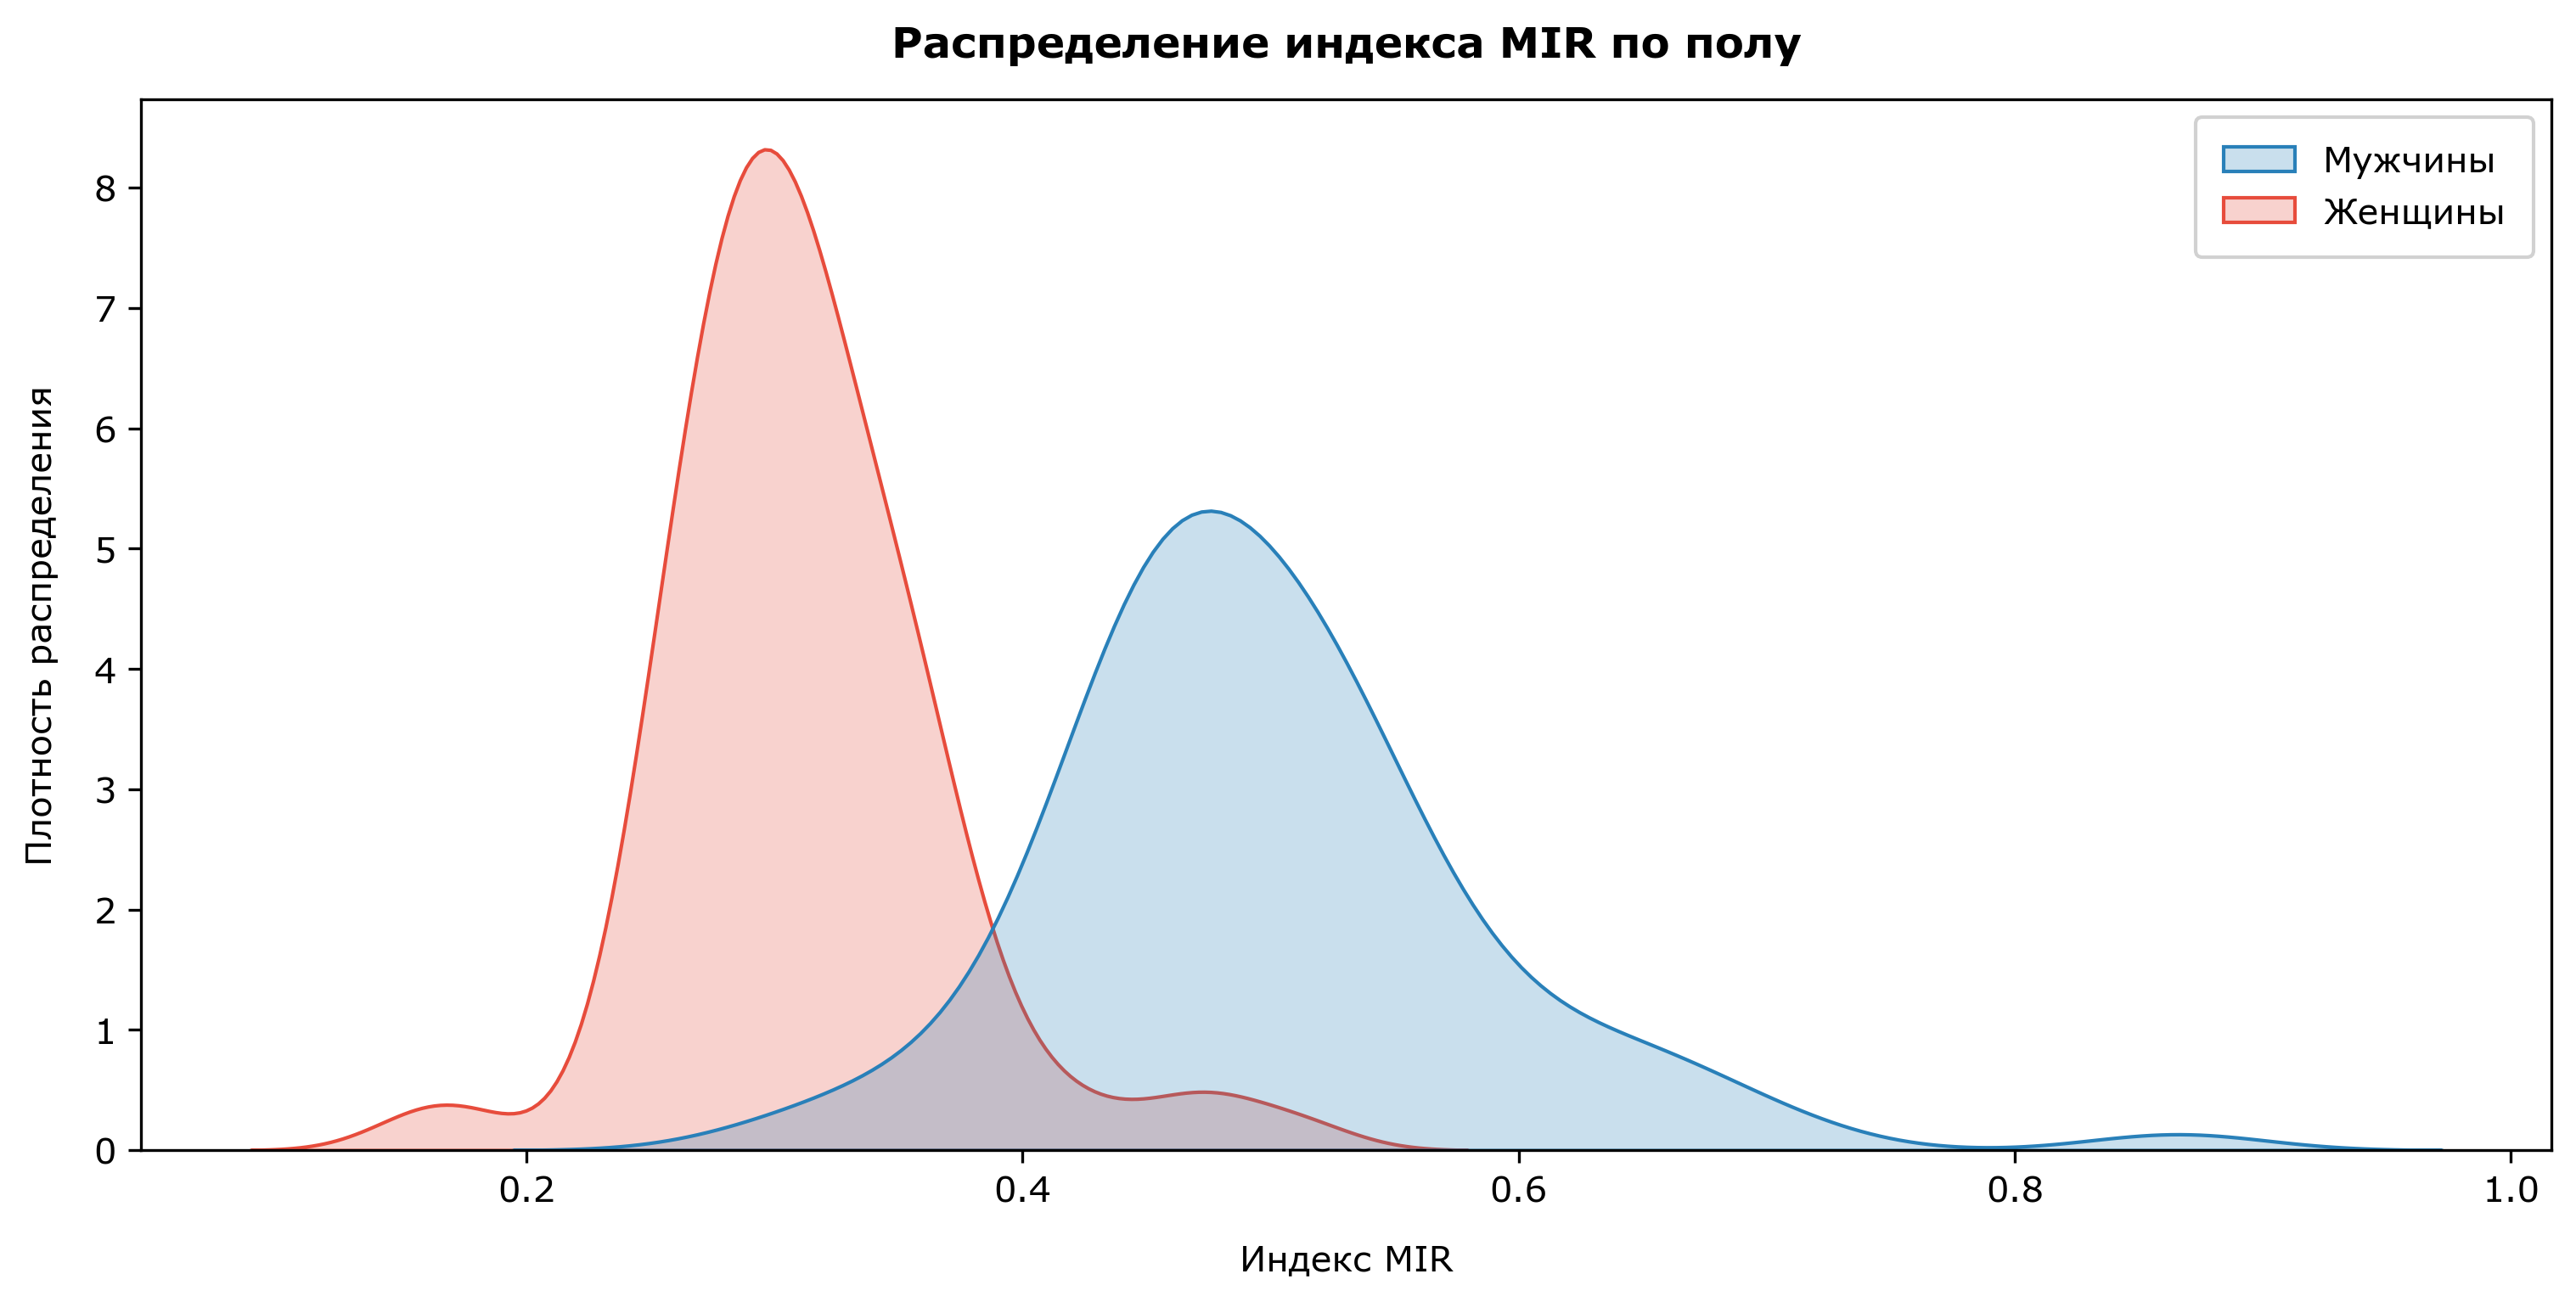

In [242]:
df_mir_male = calculate_mir(year=2023, sex="Мужчины")
df_mir_fem = calculate_mir(year=2023, sex="Женщины")

#короче еcли это убрать все падает из-за categories так что
df_mir_male["sex"] = "Мужчины"
df_mir_fem["sex"] = "Женщины"

#объединяем оба пола в один датафрейм
df_mir_gender = pd.concat([df_mir_male, df_mir_fem], ignore_index=True)

#строим KDE-графика
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

sns.kdeplot(data=df_mir_gender, x="MIR", hue="sex", common_norm=False, fill=True, palette={"Мужчины": "#2980b9", "Женщины": "#e74c3c"},ax=ax)

ax.get_legend().set_title(None)
ax.set_title("Распределение индекса MIR по полу", pad=12)
ax.set_xlabel("Индекс MIR")
ax.set_ylabel("Плотность распределения")

plt.show()

Распредление индекса MIR по полу наглядно демонстрирует ощутимое гендерное различие в исходах онкологических заболеваний. Кривая для женщин имеет выраженный пик в районе ~0.30 и компактный разброс, что свидетельствует о высокой 5-летней выживаемости и успехе ранней диагностики (преимущественно при раке молочной железы и кожи). У мужчин распределение существенно смещено вправо, с медианным пиком около ~0.48 и широким хвостом высоких значений. Это подтверждает значительно худший прогноз и повышенную летальность среди мужчин, обусловленные доминированием более агрессивных форм рака (орг. дыхания и ЖКТ) и более поздней обращаемостью за медицинской помощью.

Text(0.5, 0, 'Случаев на 100 тыс. населения')

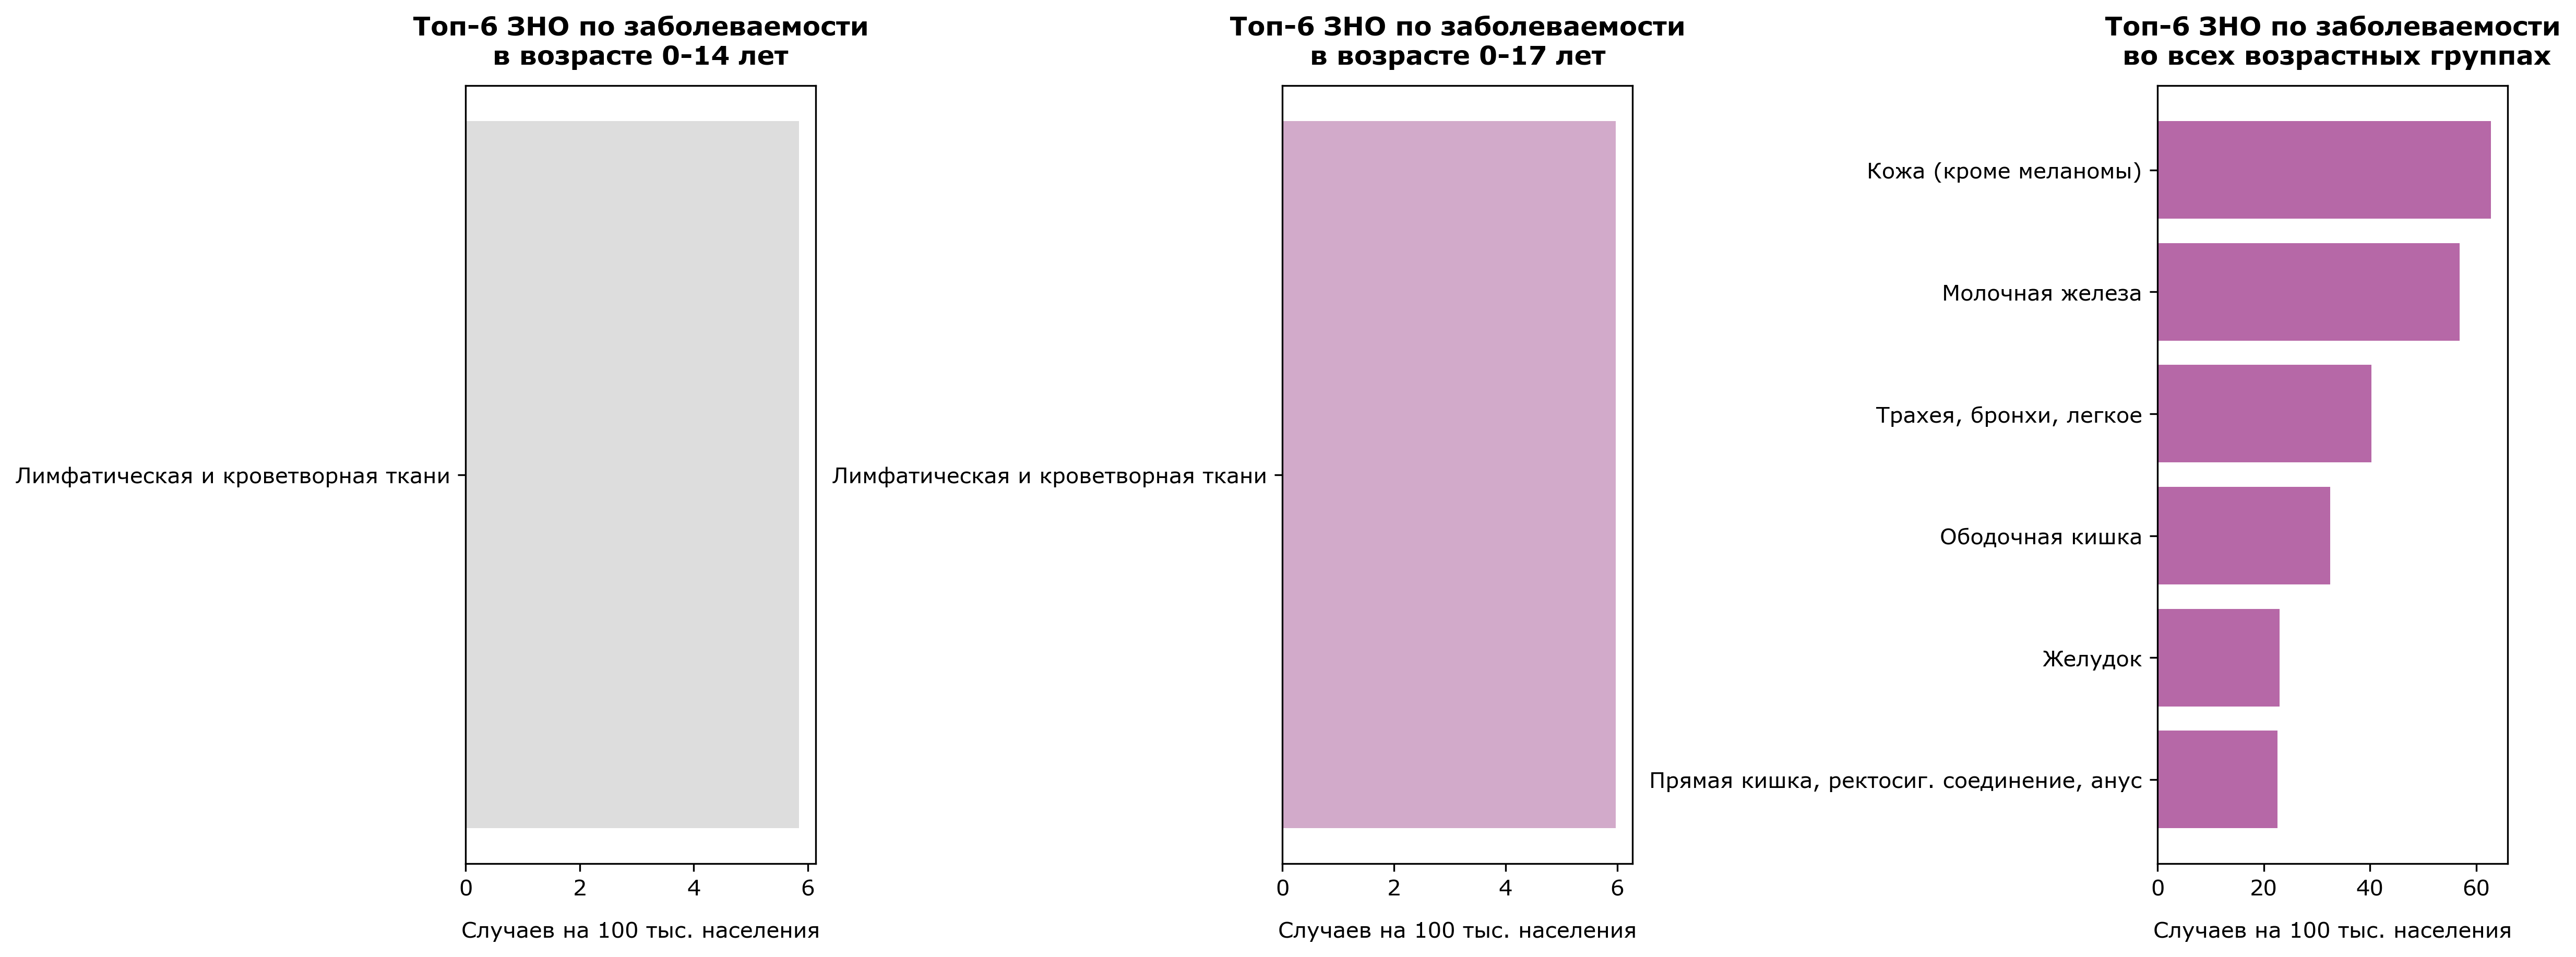

In [18]:
#делаем срезы по возрастным группам
df_014 = get_oncology_slice(
    indicator="Общий коэффициент заболеваемости",
    year=2023,
    sex="Оба пола",
    age="0-14 лет",
    nosology_name="all",
    object_level="Страна"
)

df_017 = get_oncology_slice(
    indicator="Общий коэффициент заболеваемости",
    year=2023,
    sex="Оба пола",
    age="0-17 лет",
    nosology_name="all",
    object_level="Страна"
)

df_total = get_oncology_slice(
    indicator="Общий коэффициент заболеваемости",
    year=2023,
    sex="Оба пола",
    age="Всего",
    nosology_name="all",
    object_level="Страна"
)

#удаляем аггрегированную категорию
df_014 = df_014[df_014["nosology_name"] != "Все злокачественные новообразования"]
df_017 = df_017[df_017["nosology_name"] != "Все злокачественные новообразования"]
df_total = df_total[df_total["nosology_name"] != "Все злокачественные новообразования"]

#смотрим топ-6 по группам
top_014_nos = df_014.sort_values("indicator_value", ascending=True).tail(6)
top_017_nos = df_017.sort_values("indicator_value", ascending=True).tail(6)
top_tot_nos = df_total.sort_values("indicator_value", ascending=True).tail(6)

#строим барплоты
fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

#0-14
axes[0].barh(top_014_nos["nosology_name"], top_014_nos["indicator_value"], color="#d8d8d8", alpha=0.85)
axes[0].set_title("Топ-6 ЗНО по заболеваемости\nв возрасте 0-14 лет", pad=10)
axes[0].set_xlabel("Случаев на 100 тыс. населения")

#0-17
axes[1].barh(top_017_nos["nosology_name"], top_017_nos["indicator_value"], color="#cb9bc1", alpha=0.85)
axes[1].set_title("Топ-6 ЗНО по заболеваемости\nв возрасте 0-17 лет", pad=10)
axes[1].set_xlabel("Случаев на 100 тыс. населения")

#total
axes[2].barh(top_tot_nos["nosology_name"], top_tot_nos["indicator_value"], color="#aa4d98", alpha=0.85)
axes[2].set_title("Топ-6 ЗНО по заболеваемости\n во всех возрастных группах", pad=10)
axes[2].set_xlabel("Случаев на 100 тыс. населения")


Text(0.5, 0, 'Смертей на 100 тыс. населения')

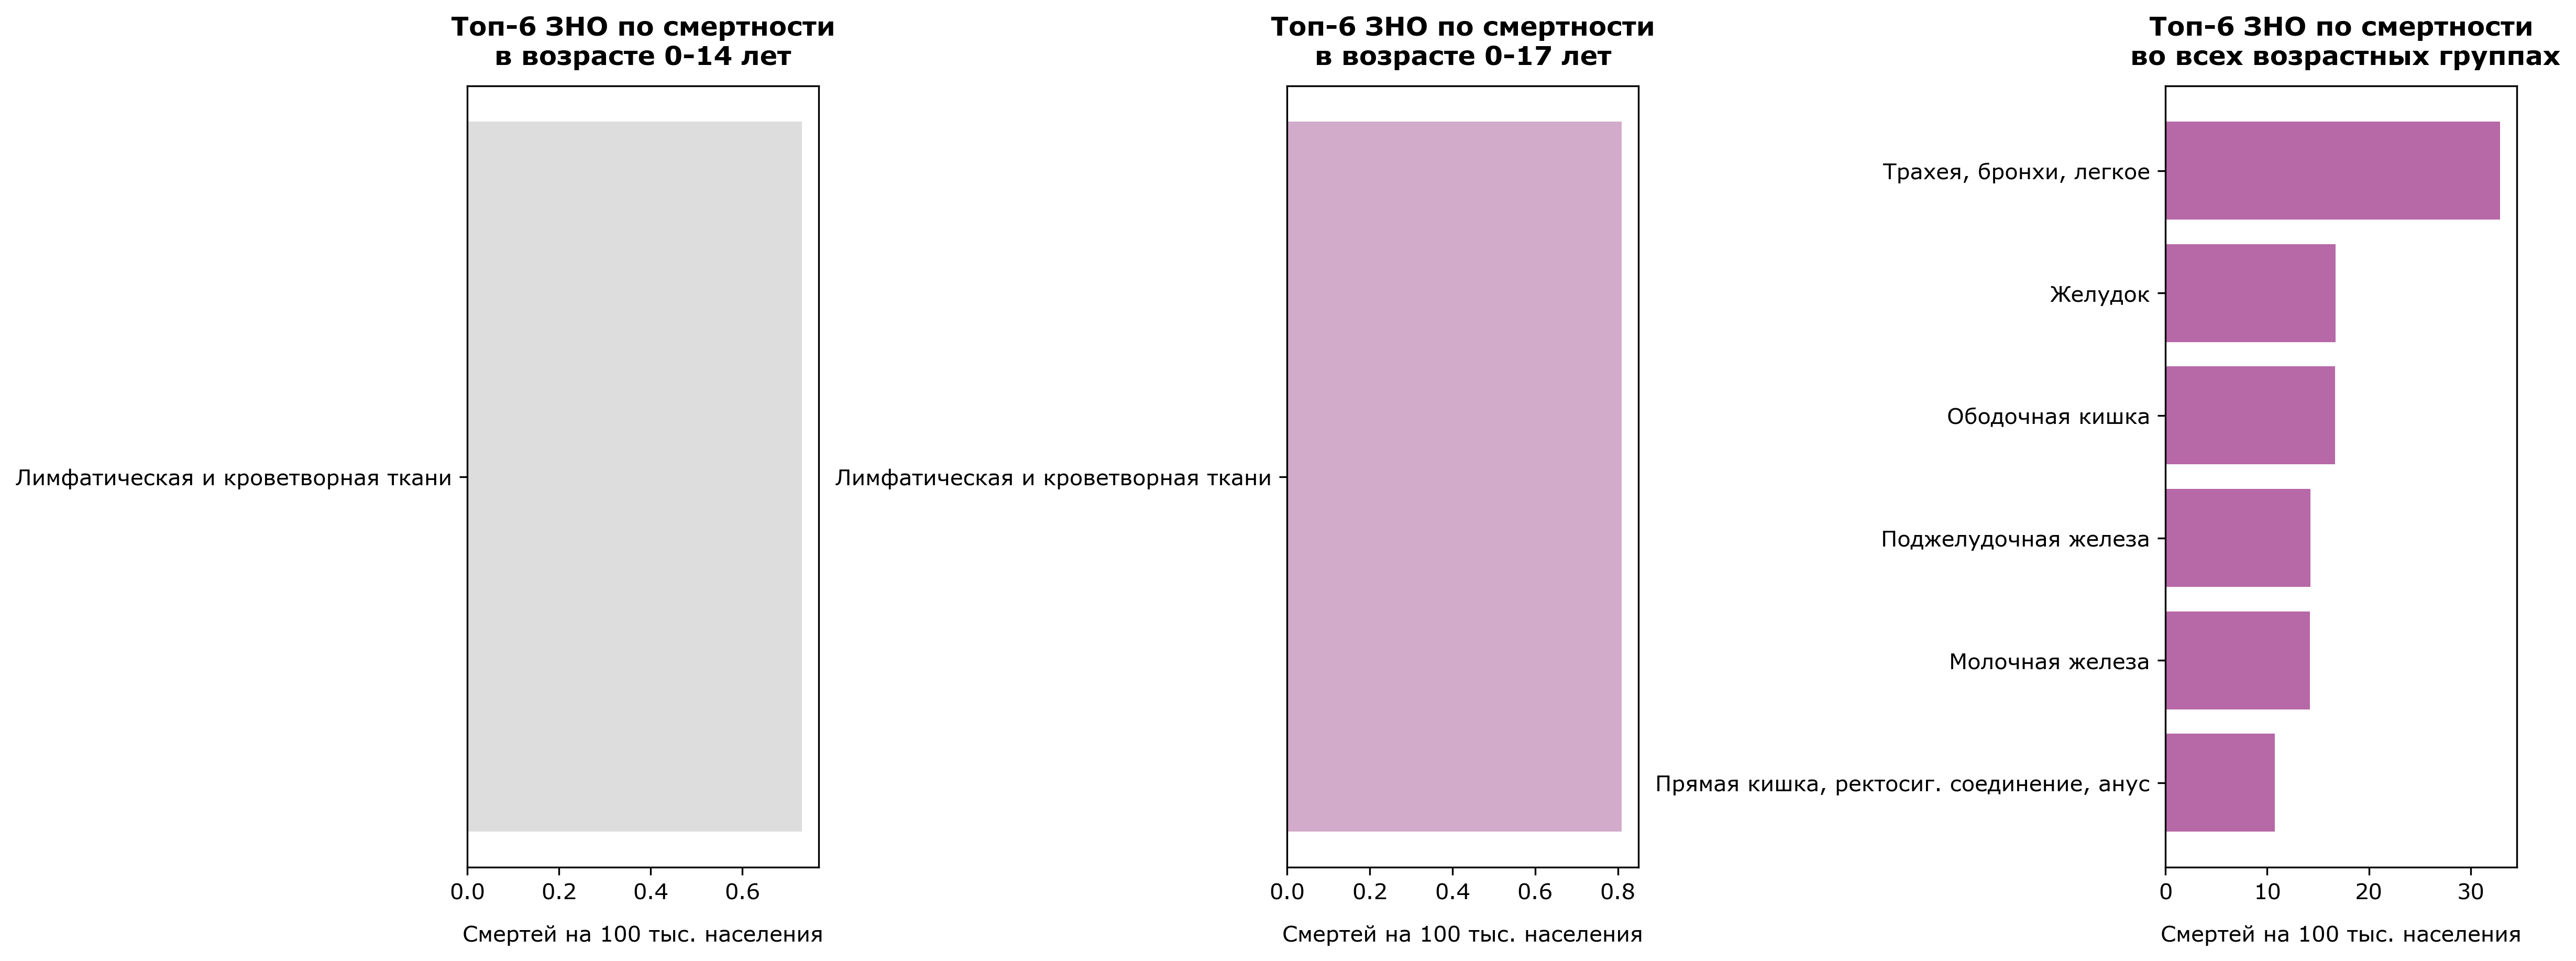

In [17]:
#делаем срезы по возрастным группам
df_014 = get_oncology_slice(
    indicator="Общий коэффициент смертности",
    year=2023,
    sex="Оба пола",
    age="0-14 лет",
    nosology_name="all",
    object_level="Страна"
)

df_017 = get_oncology_slice(
    indicator="Общий коэффициент смертности",
    year=2023,
    sex="Оба пола",
    age="0-17 лет",
    nosology_name="all",
    object_level="Страна"
)

df_total = get_oncology_slice(
    indicator="Общий коэффициент смертности",
    year=2023,
    sex="Оба пола",
    age="Всего",
    nosology_name="all",
    object_level="Страна"
)

#удаляем аггрегированную категорию
df_014 = df_014[df_014["nosology_name"] != "Все злокачественные новообразования"]
df_017 = df_017[df_017["nosology_name"] != "Все злокачественные новообразования"]
df_total = df_total[df_total["nosology_name"] != "Все злокачественные новообразования"]
df_014 = df_014[df_014["nosology_name"] != "Все причины смерти"]
df_017 = df_017[df_017["nosology_name"] != "Все причины смерти"]
df_total = df_total[df_total["nosology_name"] != "Все причины смерти"]

#смотрим топ-6 по группам
top_014_nos = df_014.sort_values("indicator_value", ascending=True).tail(6)
top_017_nos = df_017.sort_values("indicator_value", ascending=True).tail(6)
top_tot_nos = df_total.sort_values("indicator_value", ascending=True).tail(6)

#строим барплоты
fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

#0-14
axes[0].barh(top_014_nos["nosology_name"], top_014_nos["indicator_value"], color="#d8d8d8", alpha=0.85)
axes[0].set_title("Топ-6 ЗНО по смертности\nв возрасте 0-14 лет", pad=10)
axes[0].set_xlabel("Смертей на 100 тыс. населения")

#0-17
axes[1].barh(top_017_nos["nosology_name"], top_017_nos["indicator_value"], color="#cb9bc1", alpha=0.85)
axes[1].set_title("Топ-6 ЗНО по смертности\nв возрасте 0-17 лет", pad=10)
axes[1].set_xlabel("Смертей на 100 тыс. населения")

#total
axes[2].barh(top_tot_nos["nosology_name"], top_tot_nos["indicator_value"], color="#aa4d98", alpha=0.85)
axes[2].set_title("Топ-6 ЗНО по смертности\n во всех возрастных группах", pad=10)
axes[2].set_xlabel("Смертей на 100 тыс. населения")

Проанализировать возратсные особенности, к сожалению не представилось возможным. Т.к. датасет имеет крайне низкое качество для молодых возарстных групп.

### Итоги
Проведённое исследование онкологической обстановки в РФ (1997–2023 гг.) фиксирует важнейший структурный сдвиг: устойчивый рост первичной заболеваемости (с 430 до 675 тыс. случаев) обусловлен преимущественно демографическим фактором старения населения, тогда как планомерное падение стандартизованной смертности (с 125 до <100 на 100 тыс.) подтверждает рост качества ранней диагностики и терапевтического лечения. Однако в стране сохраняется глубокая пространственная и гендерная дифференциация: субъекты Сибири, Дальнего Востока и Северо-Запада демонстрируют повышенные показатели смертности и индекса MIR, а мужчины имеют существенно худший онкологический прогноз (медианный MIR ~0.48 против ~0.30 у женщин) вследствие доминирования агрессивных патологий органов дыхания и ЖКТ в сочетании со сдвигом выявляемости на более поздние стадии.